# Visualization - Weapon Fire activity related Spatio-temporal occupancy maps (fire-STOMs) 
# For any one match 
- Spatiol map evolution vs. epochs (10s)
- Collapsed aggregated evolution vs. epochs
- Collapsed differntiated evolution vs. epochs
  



--- Available Matches ---
[0] 36277387-28ba-4706-bc2a-fb2ba6da5365.csv
[1] 0826b896-52ee-4bb5-9d00-165e599fdaee.csv
[2] 90a645c3-6586-43b6-9a7a-ec7094696efb.csv
[3] 829f3105-4424-4079-bbcb-acfe7c3c36fb.csv
[4] 87b66b98-be62-496c-9ec4-e96eacb5b233.csv
[5] d81f91db-df63-4ffe-9d72-0c094c2e70df.csv
[6] a76f5b74-c1c0-484e-82e3-4c2737c37c08.csv
[7] 349ef7c0-77eb-4777-9d4a-80d8d2d65e6c.csv
[8] f168d5b1-8ead-493a-b835-33e7519130f4.csv
[9] 09d93ef4-ade2-431b-a550-25c0f42c8c16.csv
[10] 436da7b2-5527-4db7-9462-eb305775aa1b.csv
[11] 3a3e27ea-676f-4959-9599-8b7d11a25763.csv
[12] f5387172-ab69-4887-a31c-c4bd651ddc2a.csv
[13] 1d818114-9fa1-4656-97ec-fb2f64acb1ea.csv
[14] ad21e4f1-3d82-4700-be0f-df29ce7097bf.csv
[15] 7315b42b-397f-4ef3-afcd-6369e8a29249.csv
[16] 7d0f0ee0-f7c9-4944-bfdb-41f99865ed68.csv
[17] 0c7cfaec-0e3e-4852-908e-df2b7dcac2f3.csv
[18] 285adbd2-ef84-4caa-b358-a100f9d05767.csv
[19] 69c13bc0-0458-4755-84e4-f8e57088636f.csv
[20] 58454819-c5a9-4b2d-afcb-9f800b5775f0.csv
[21] 5f8c4089-5ce

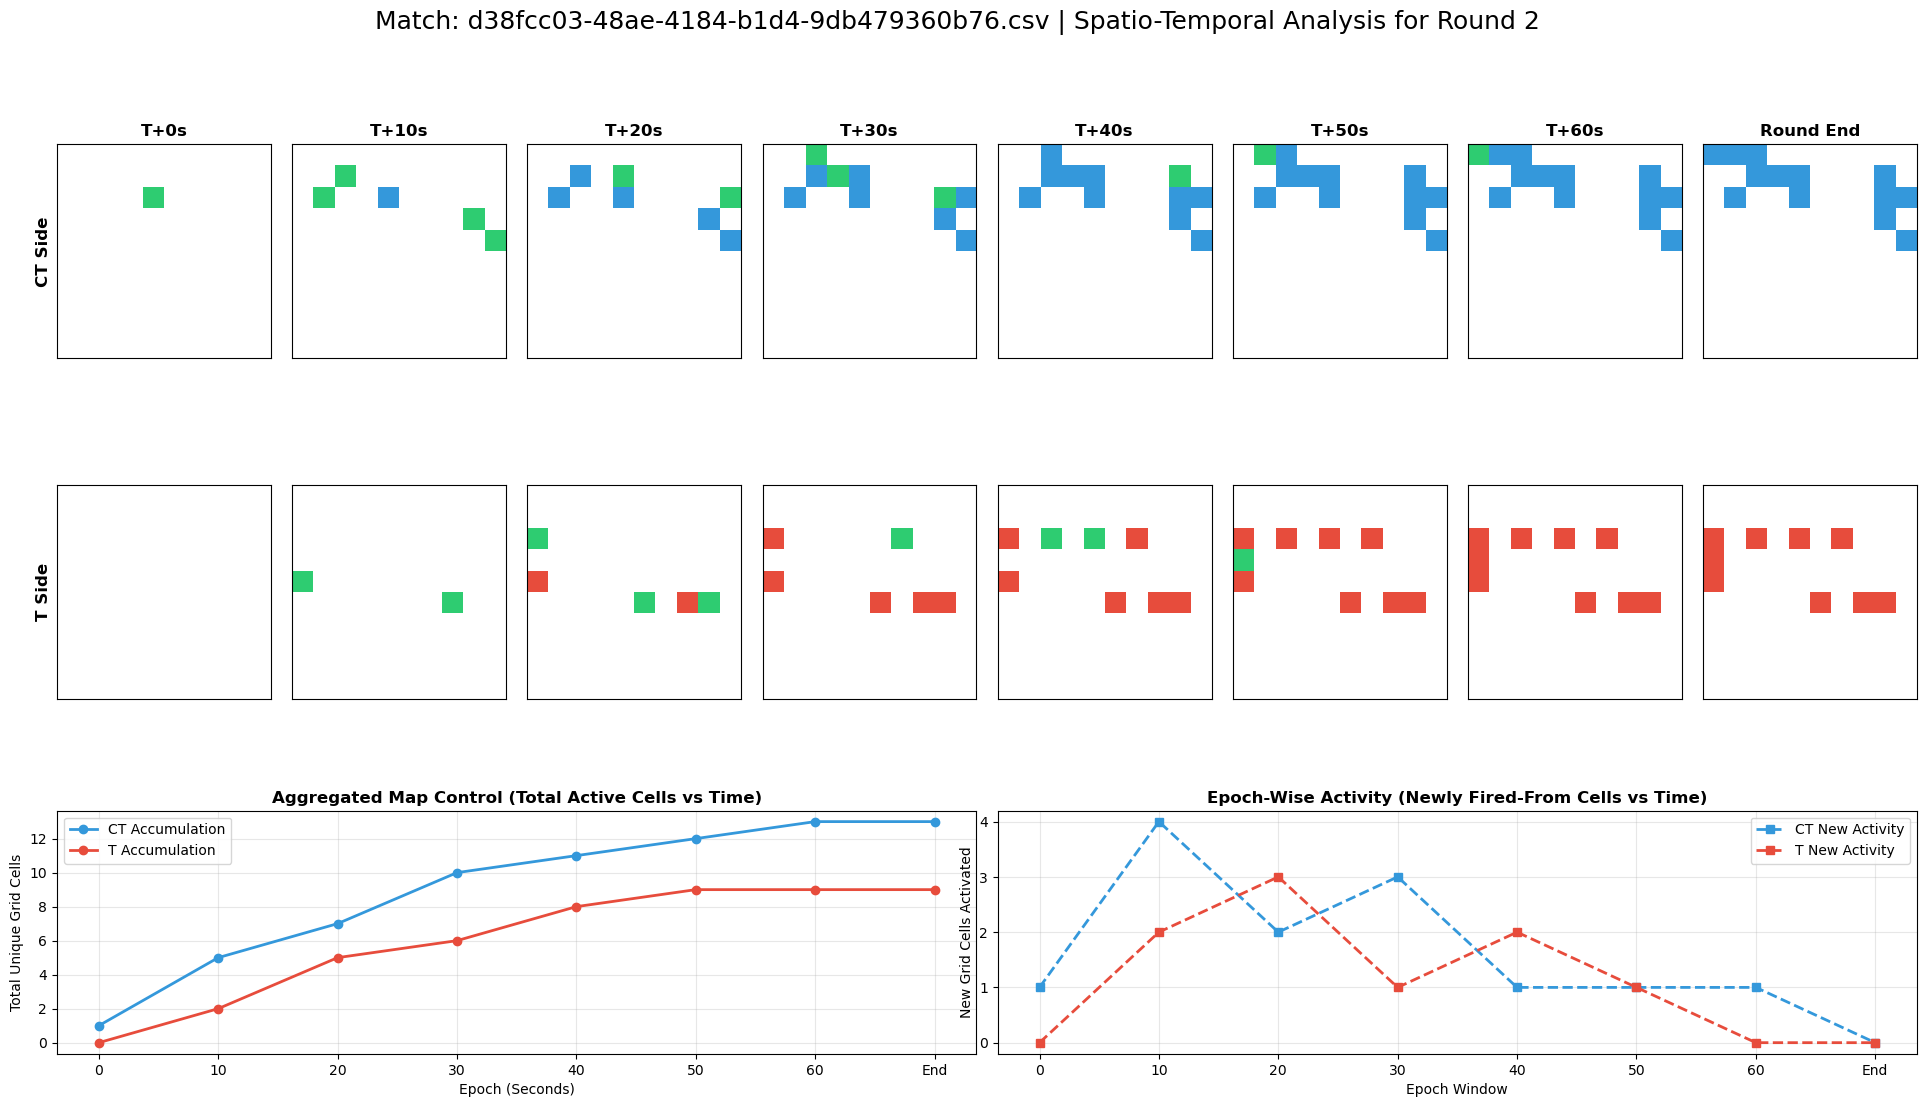

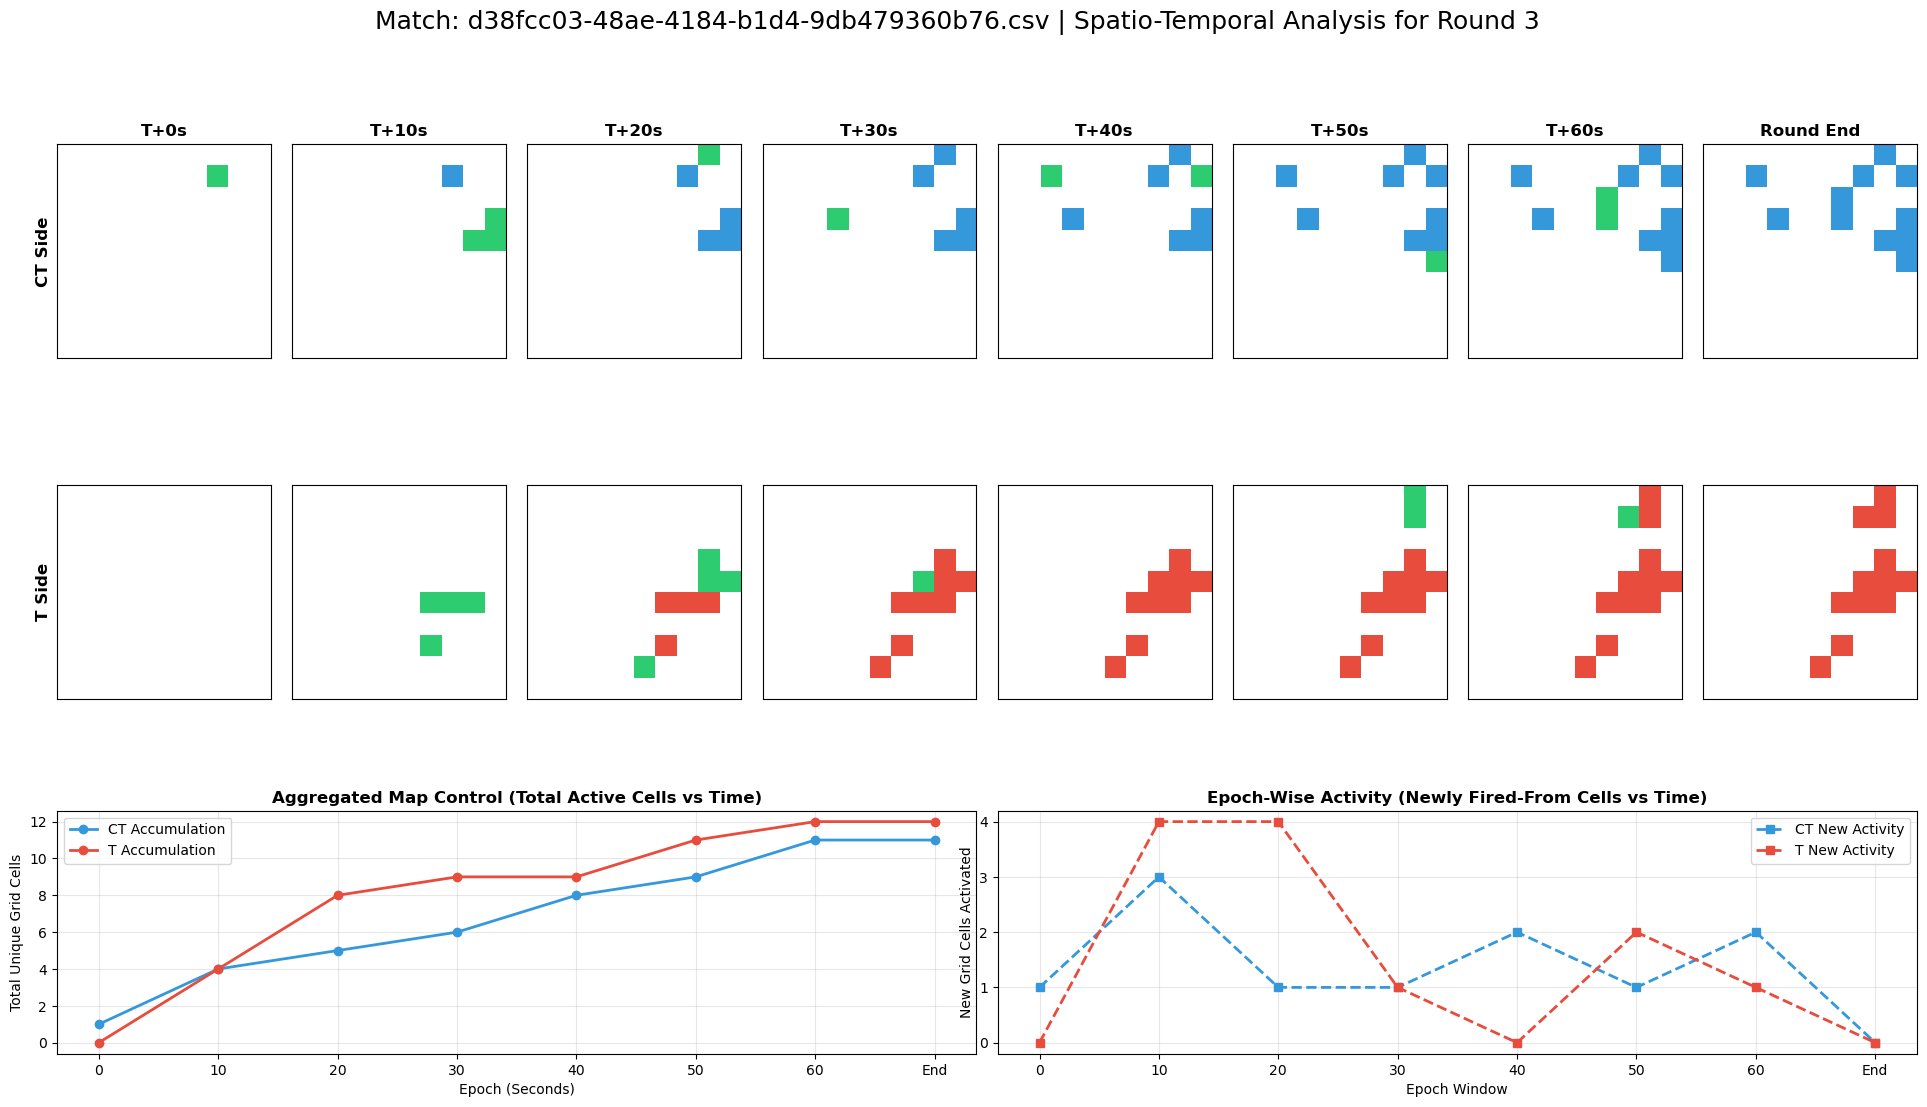

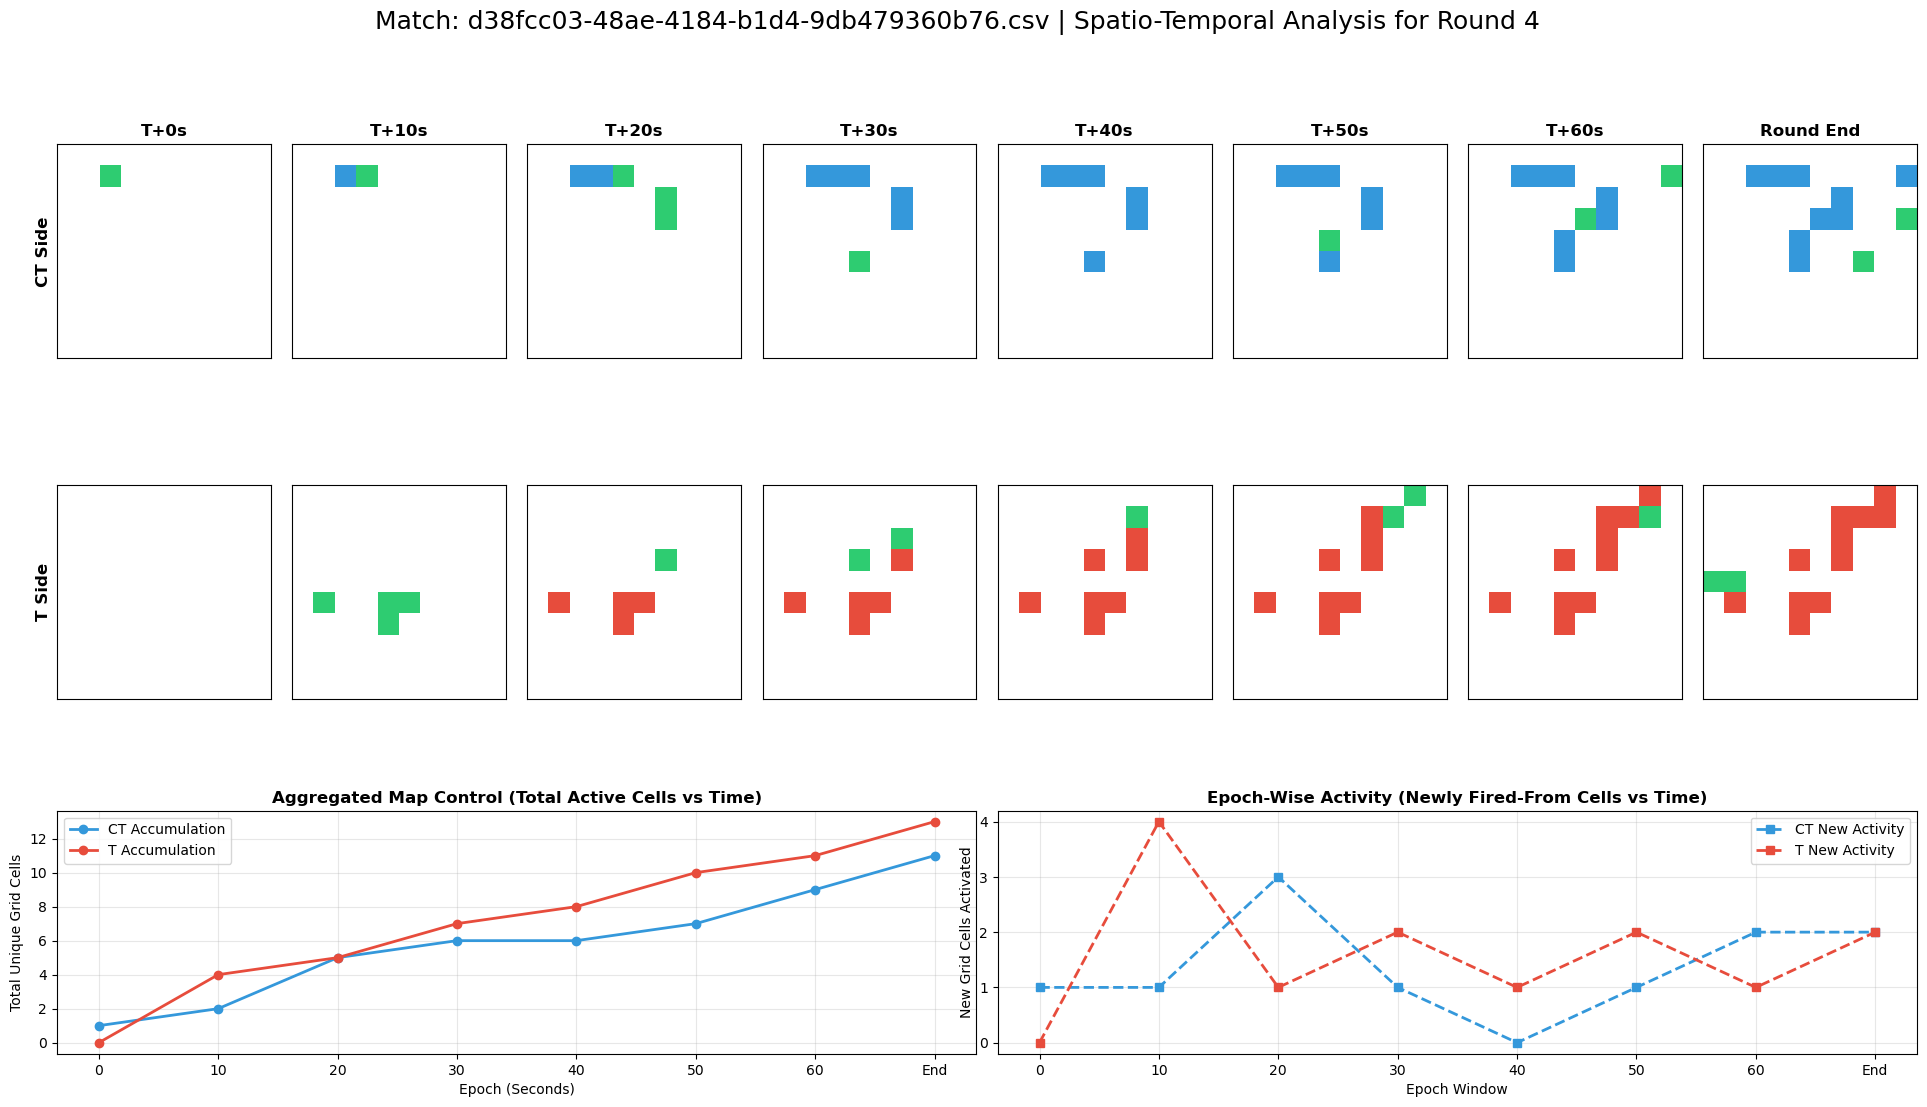

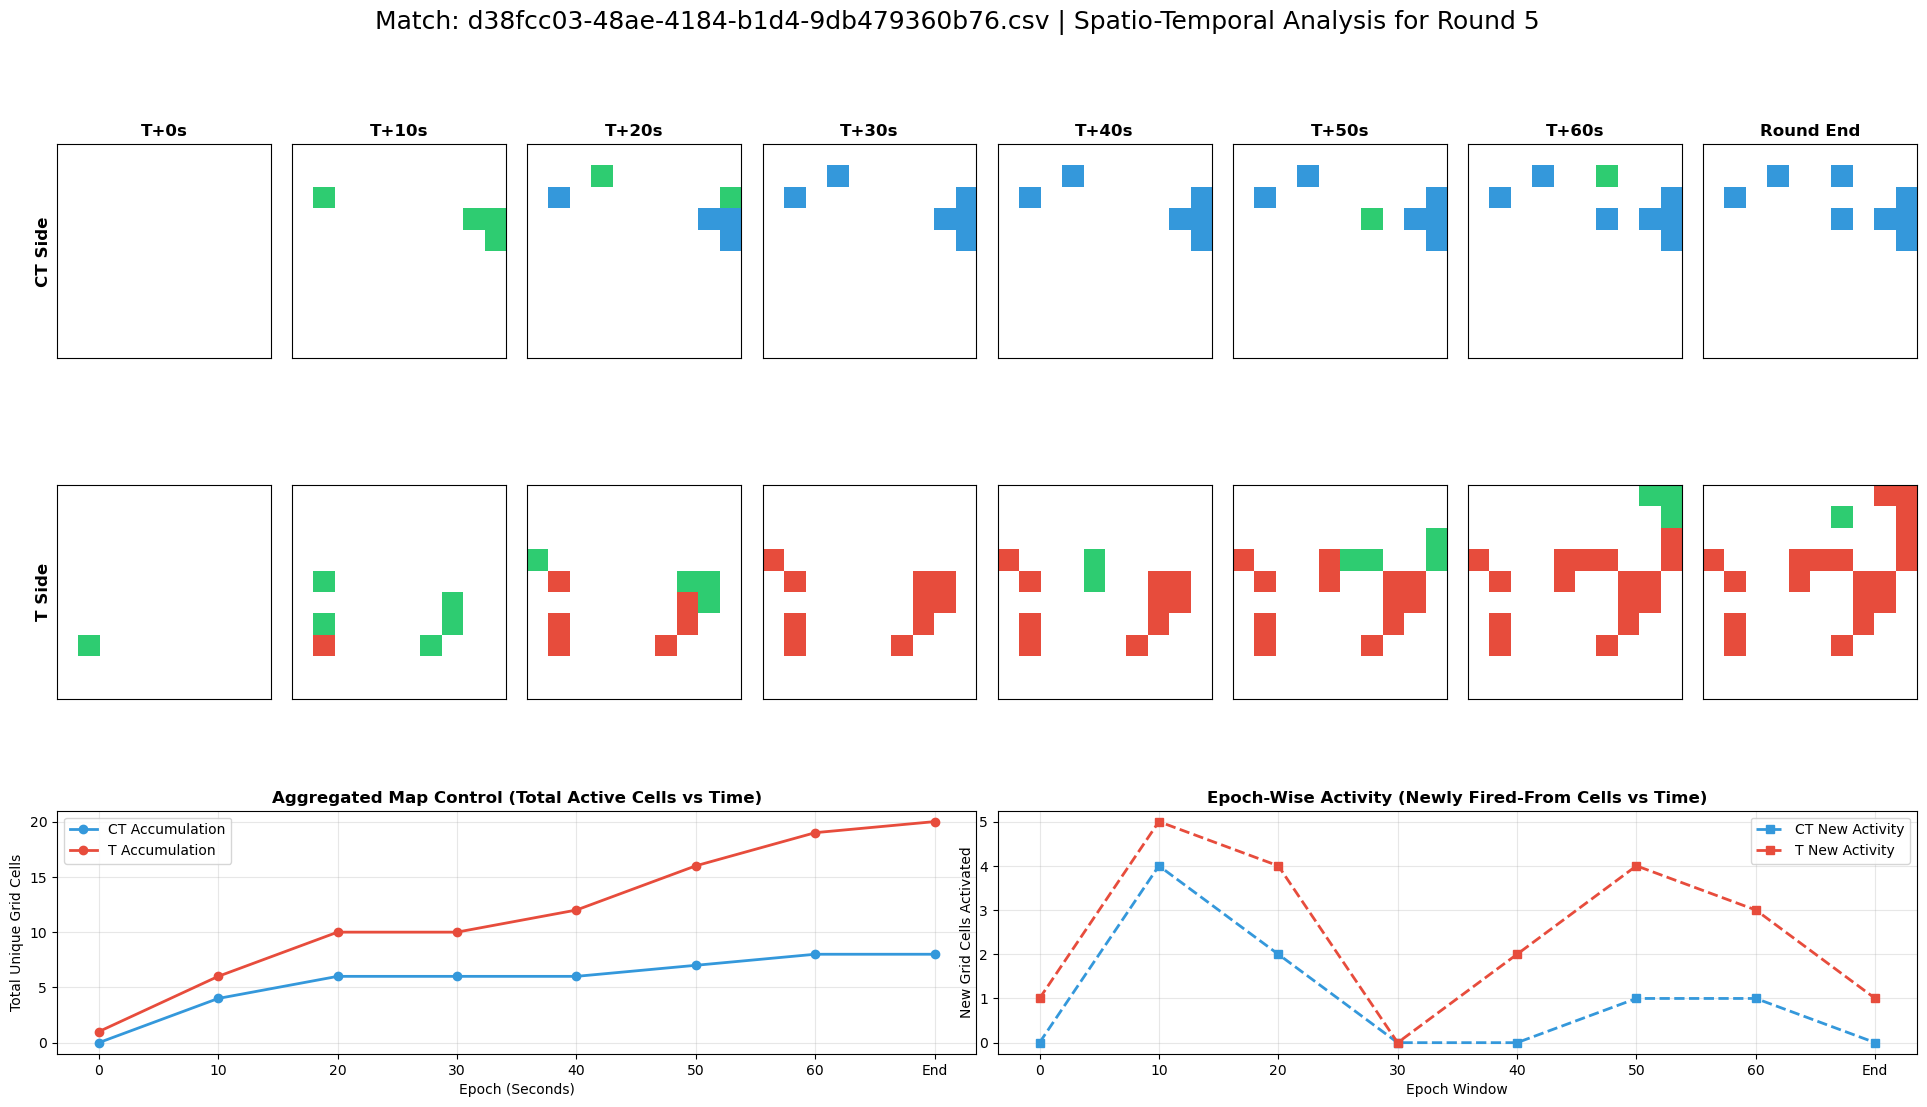

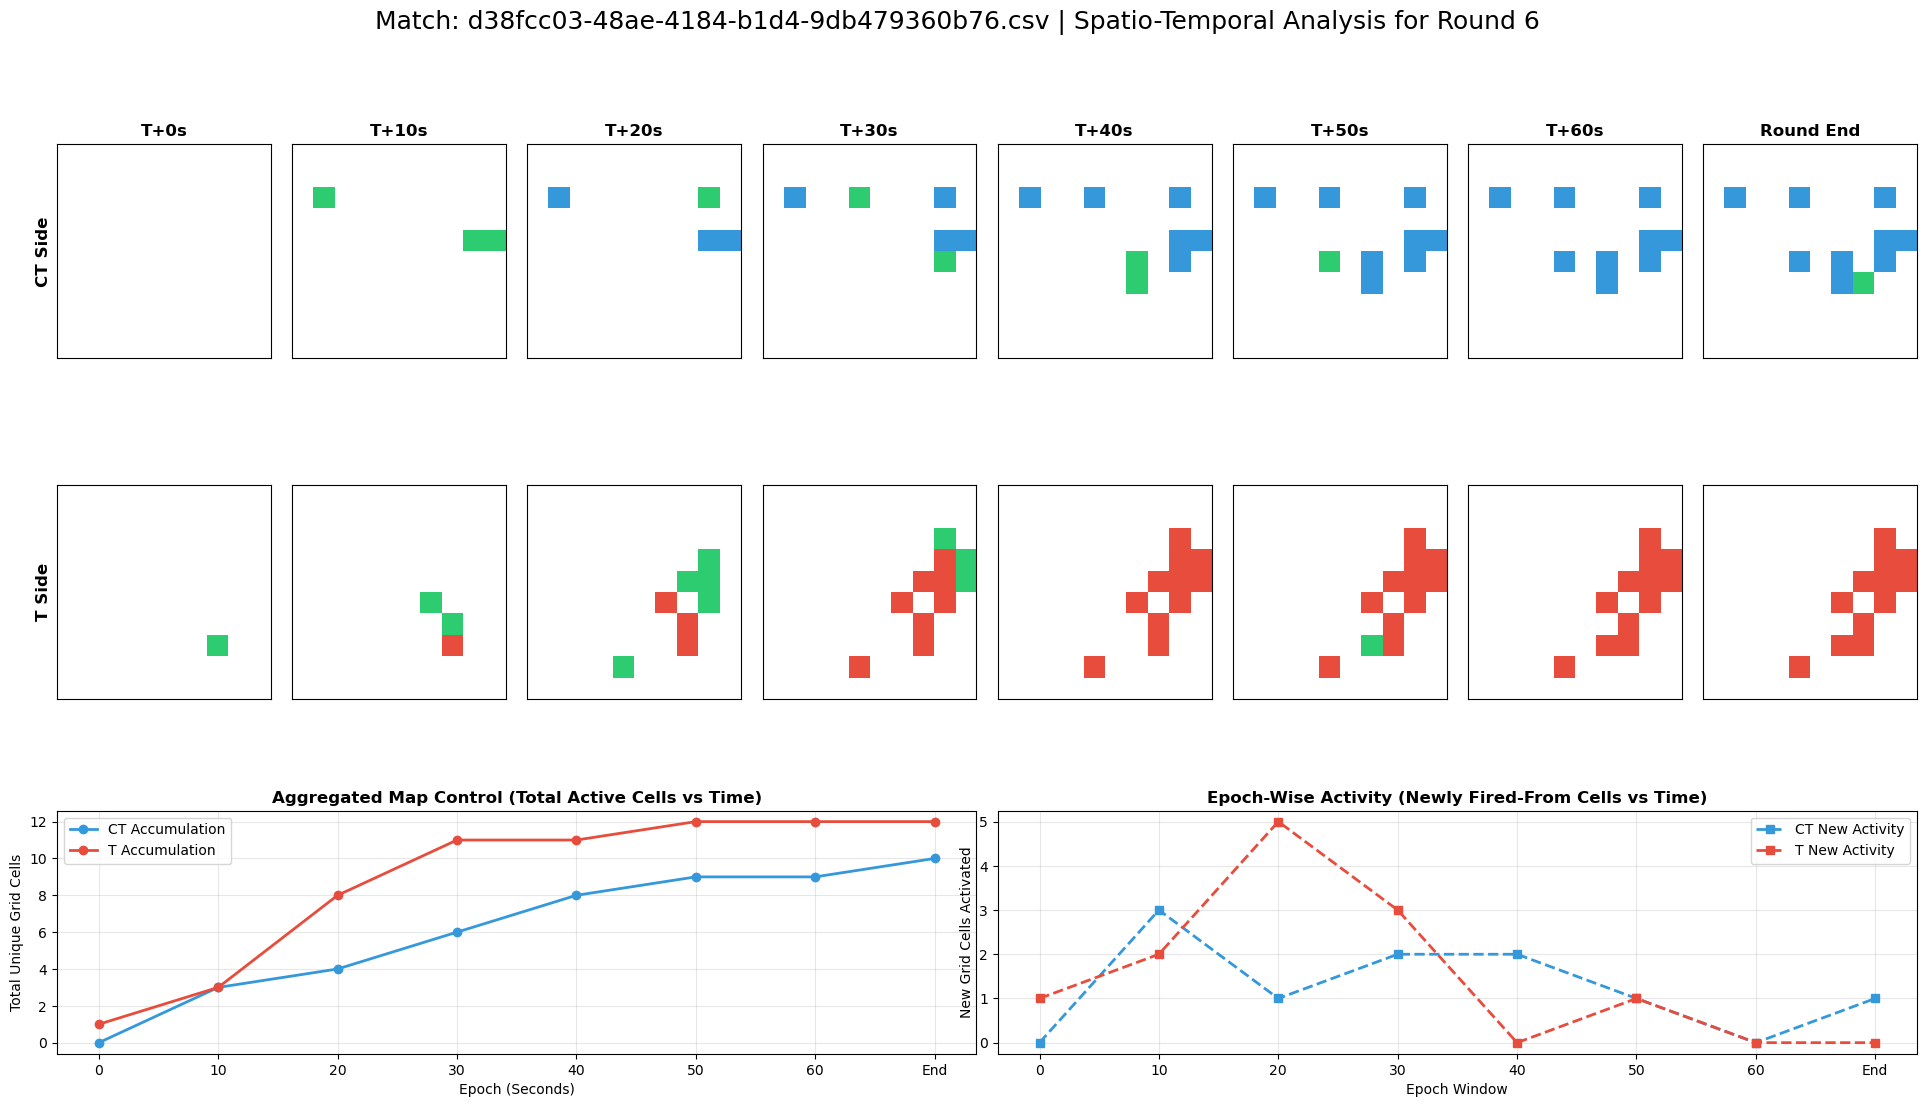

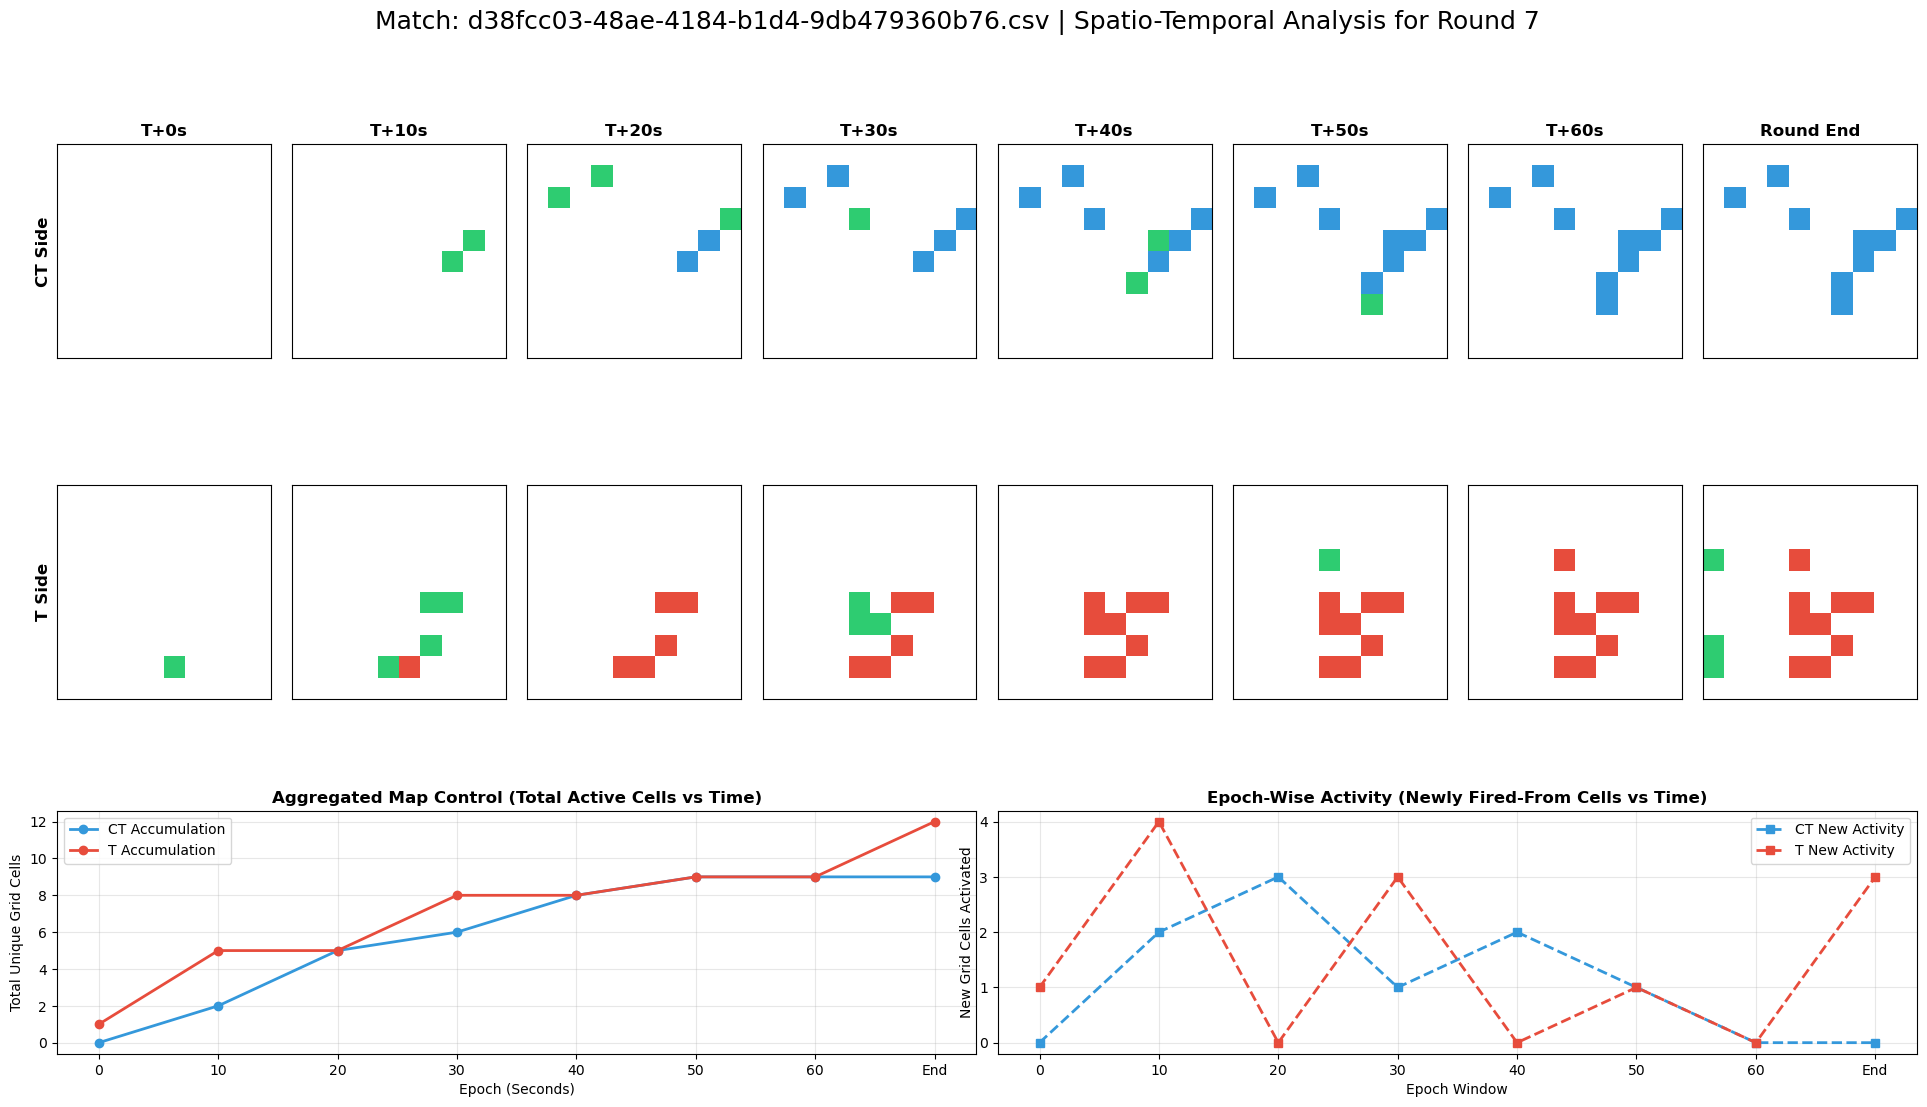

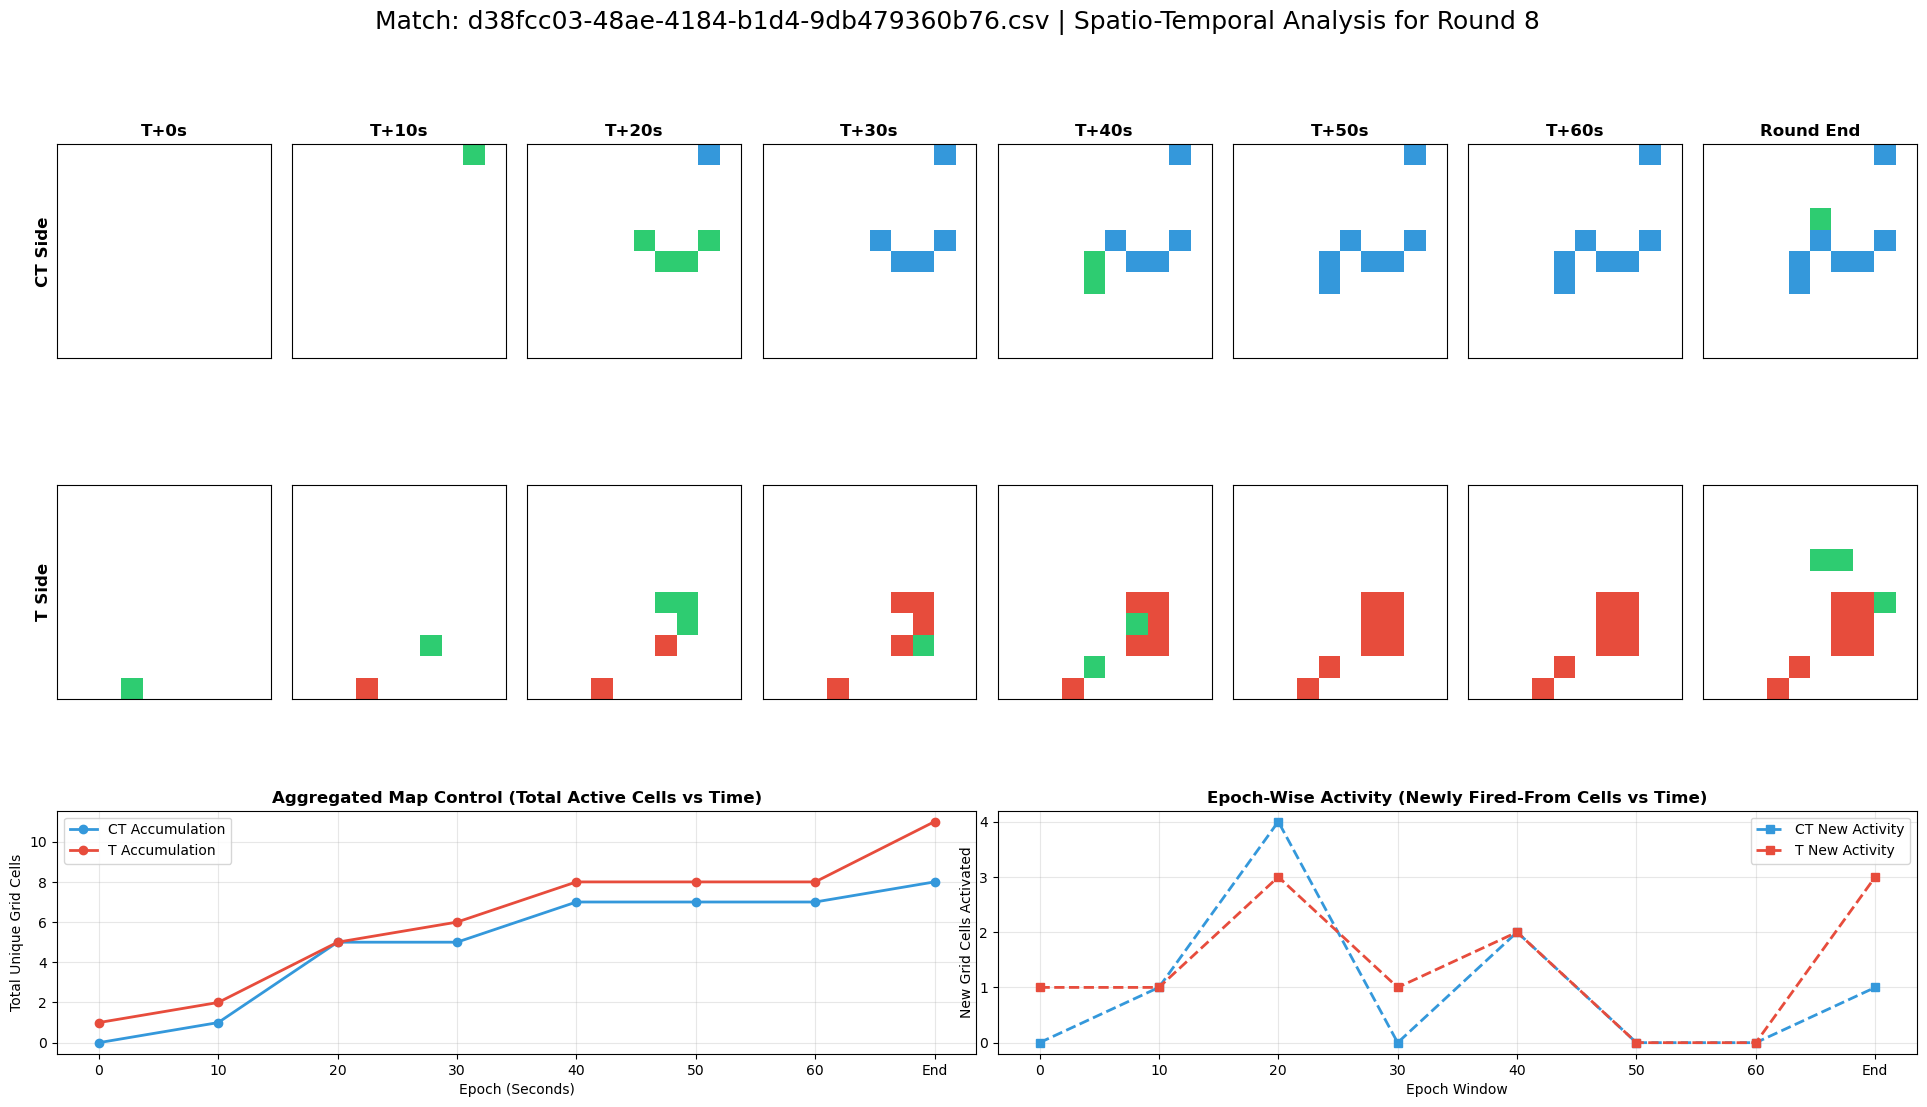

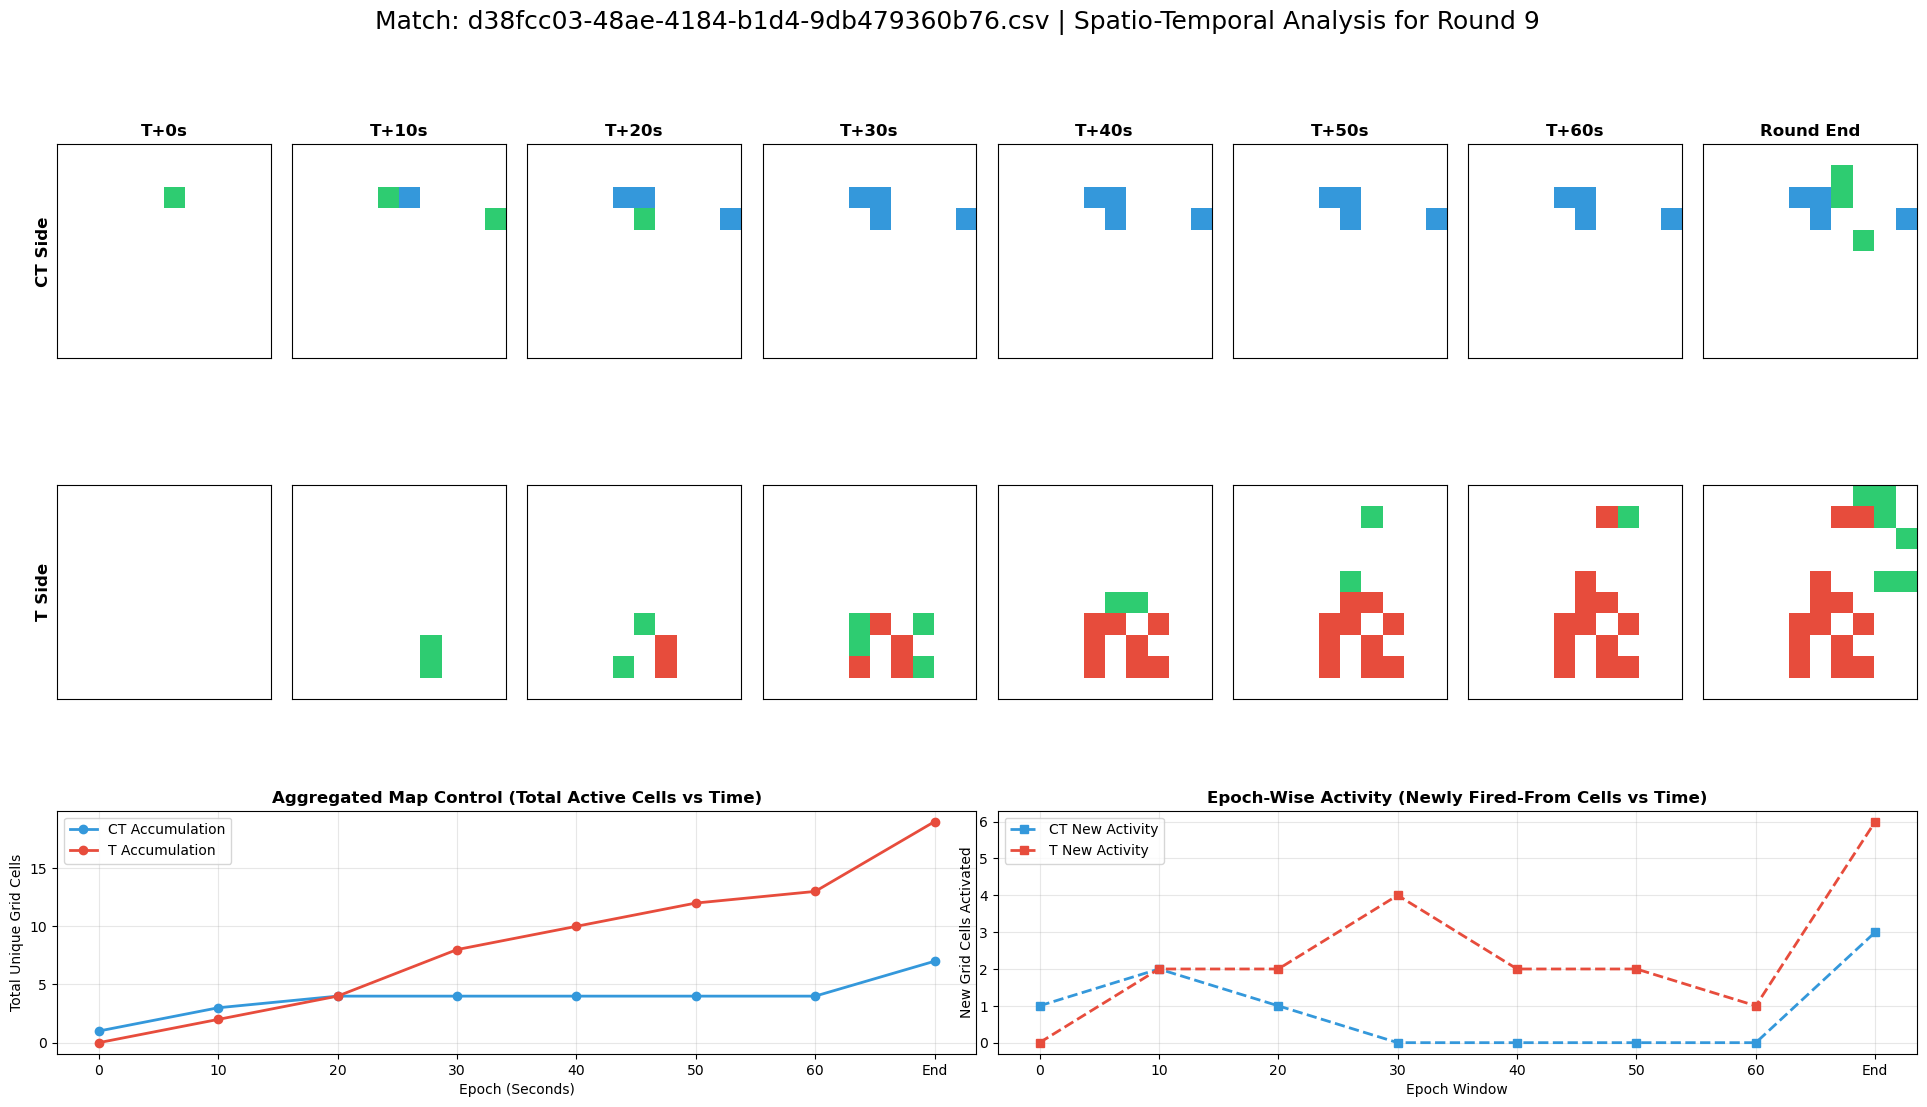

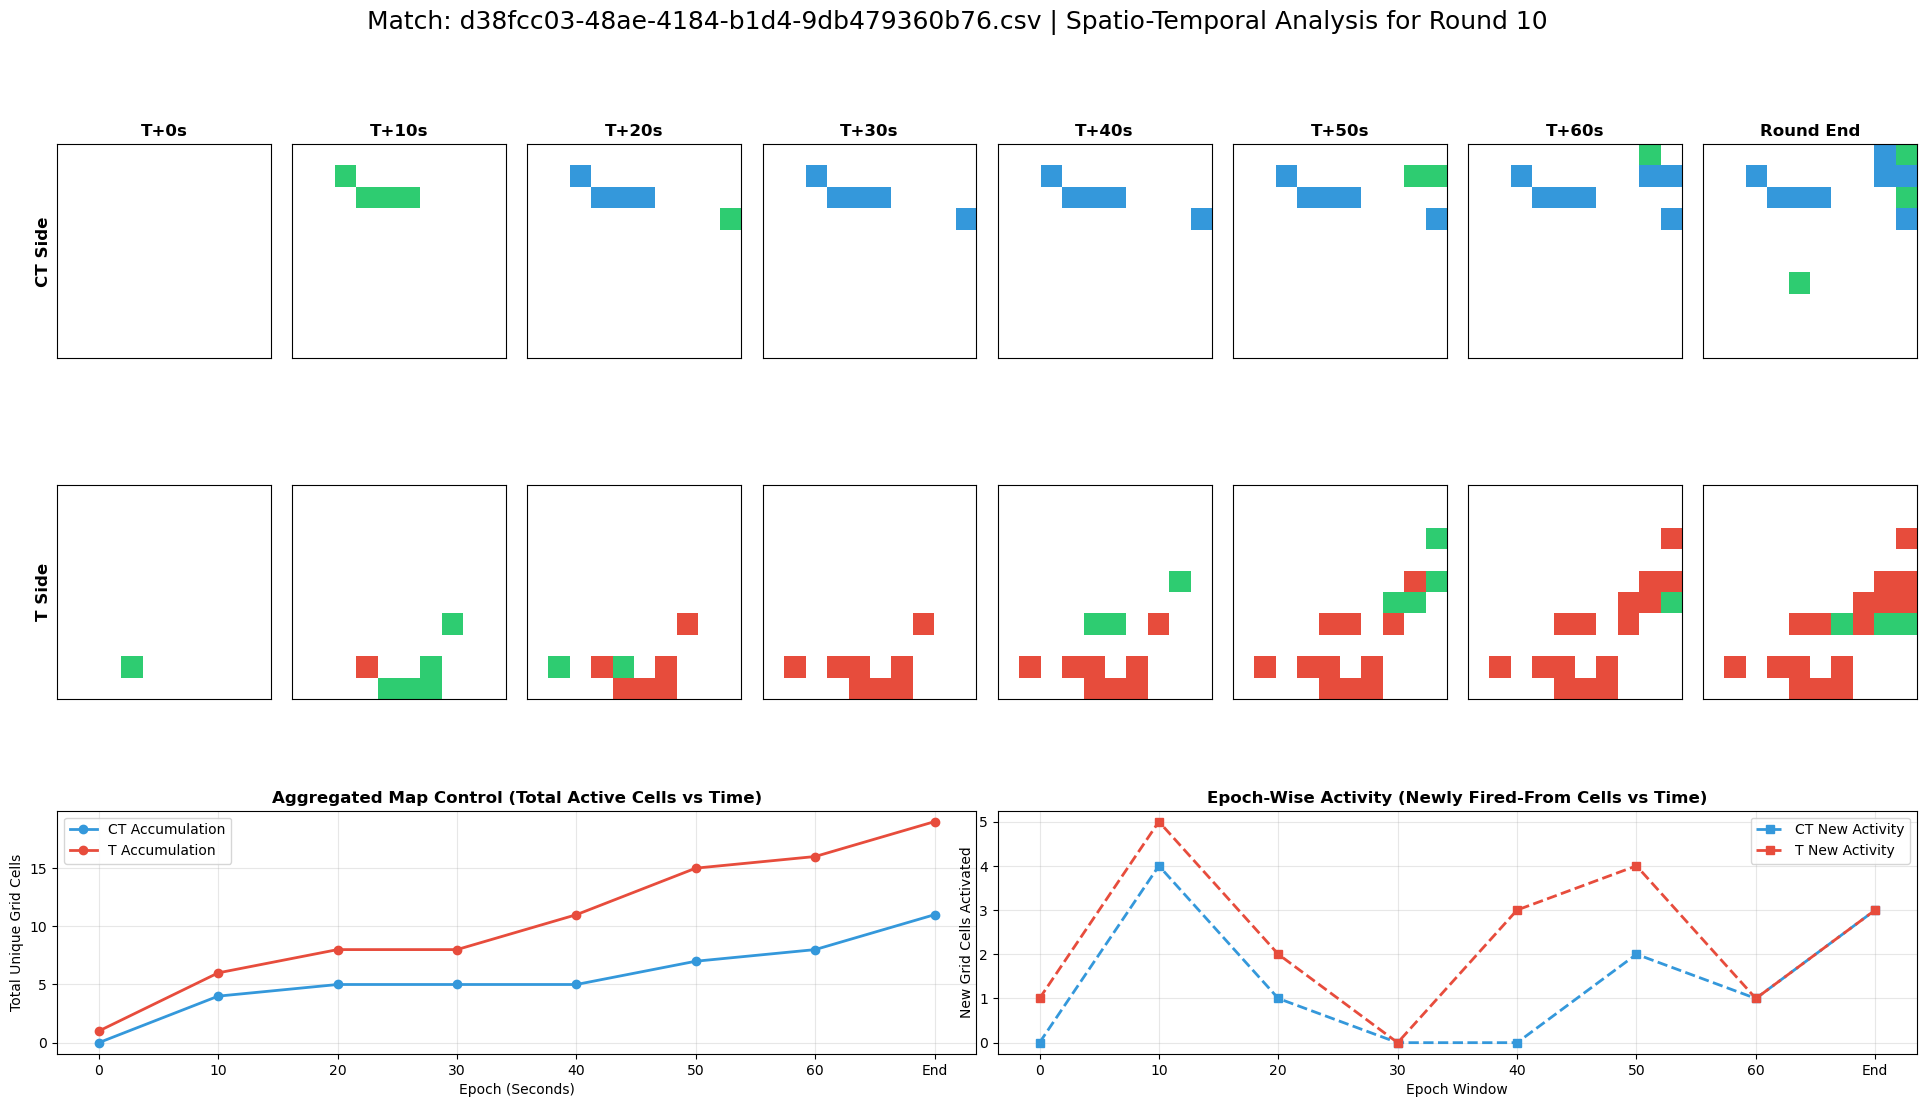

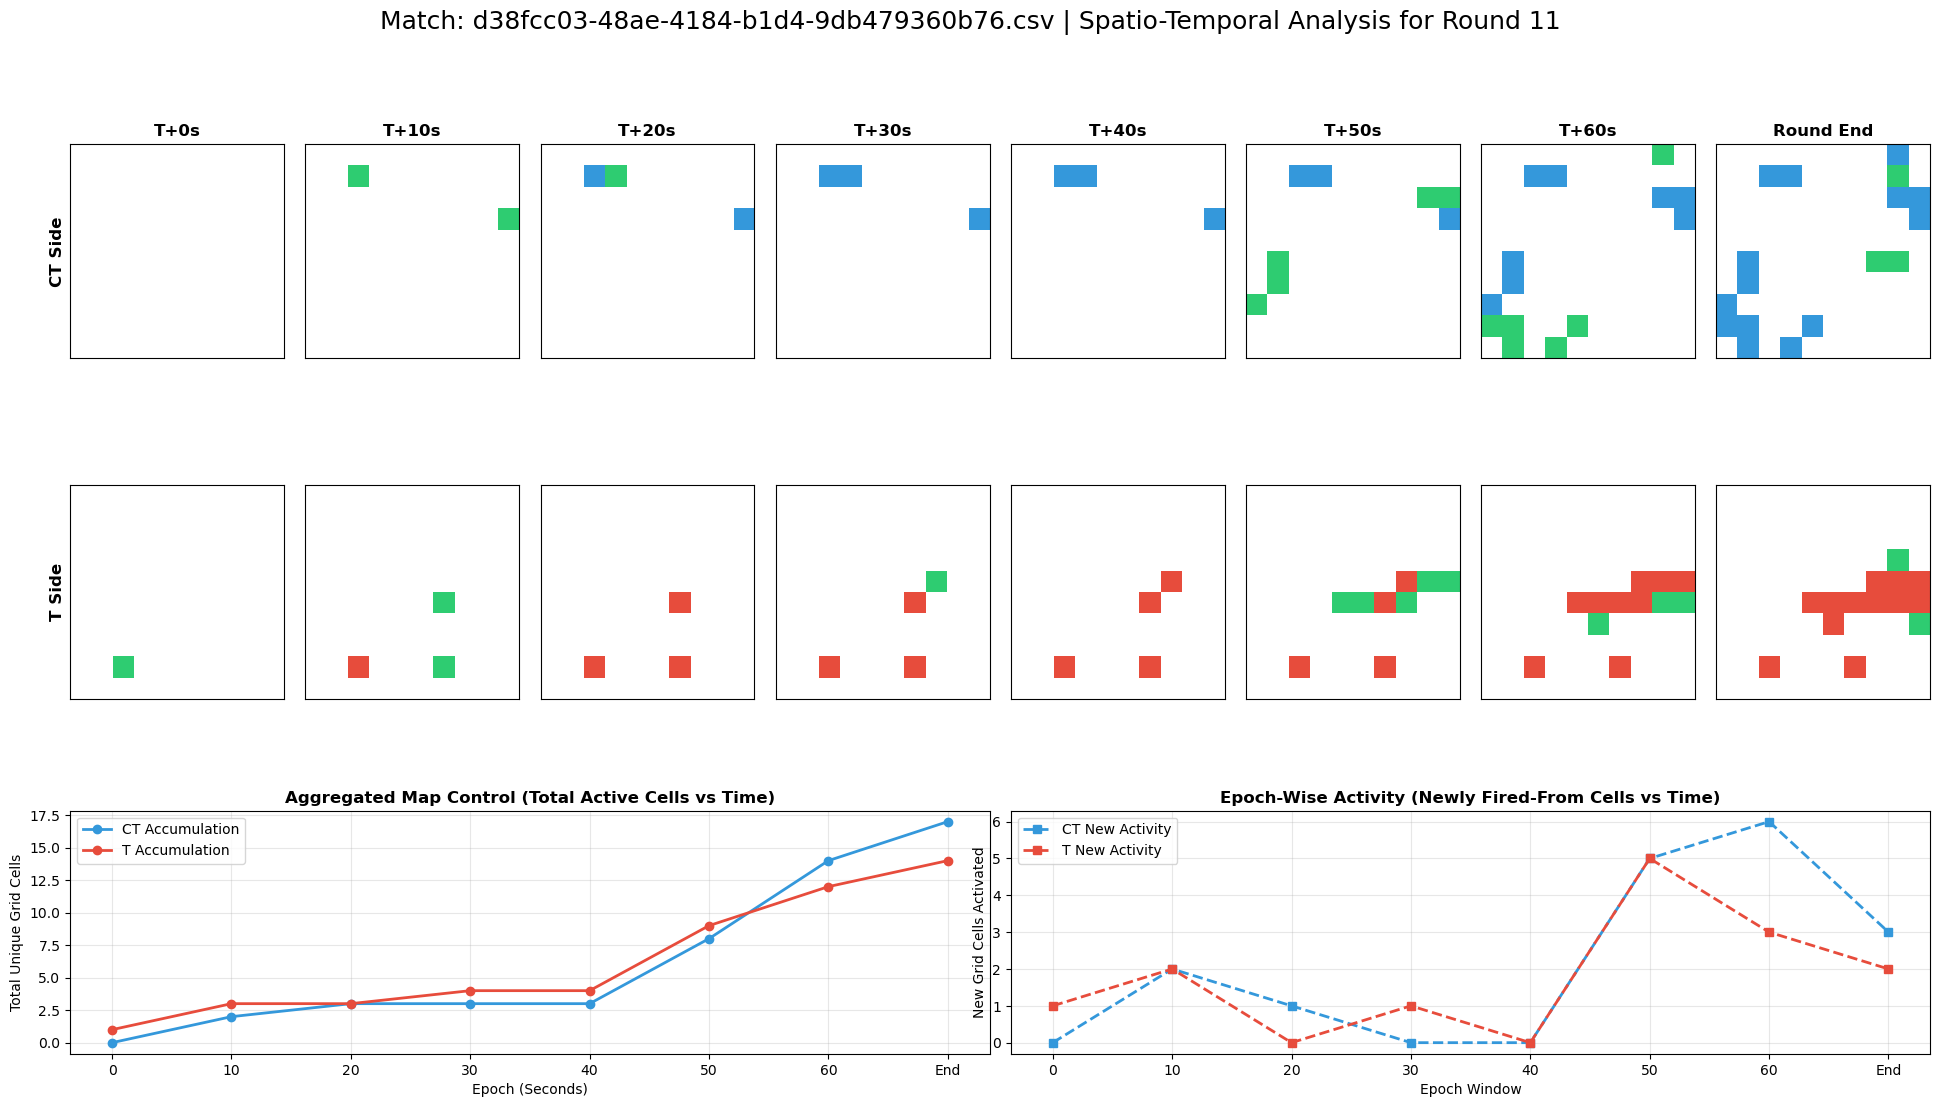

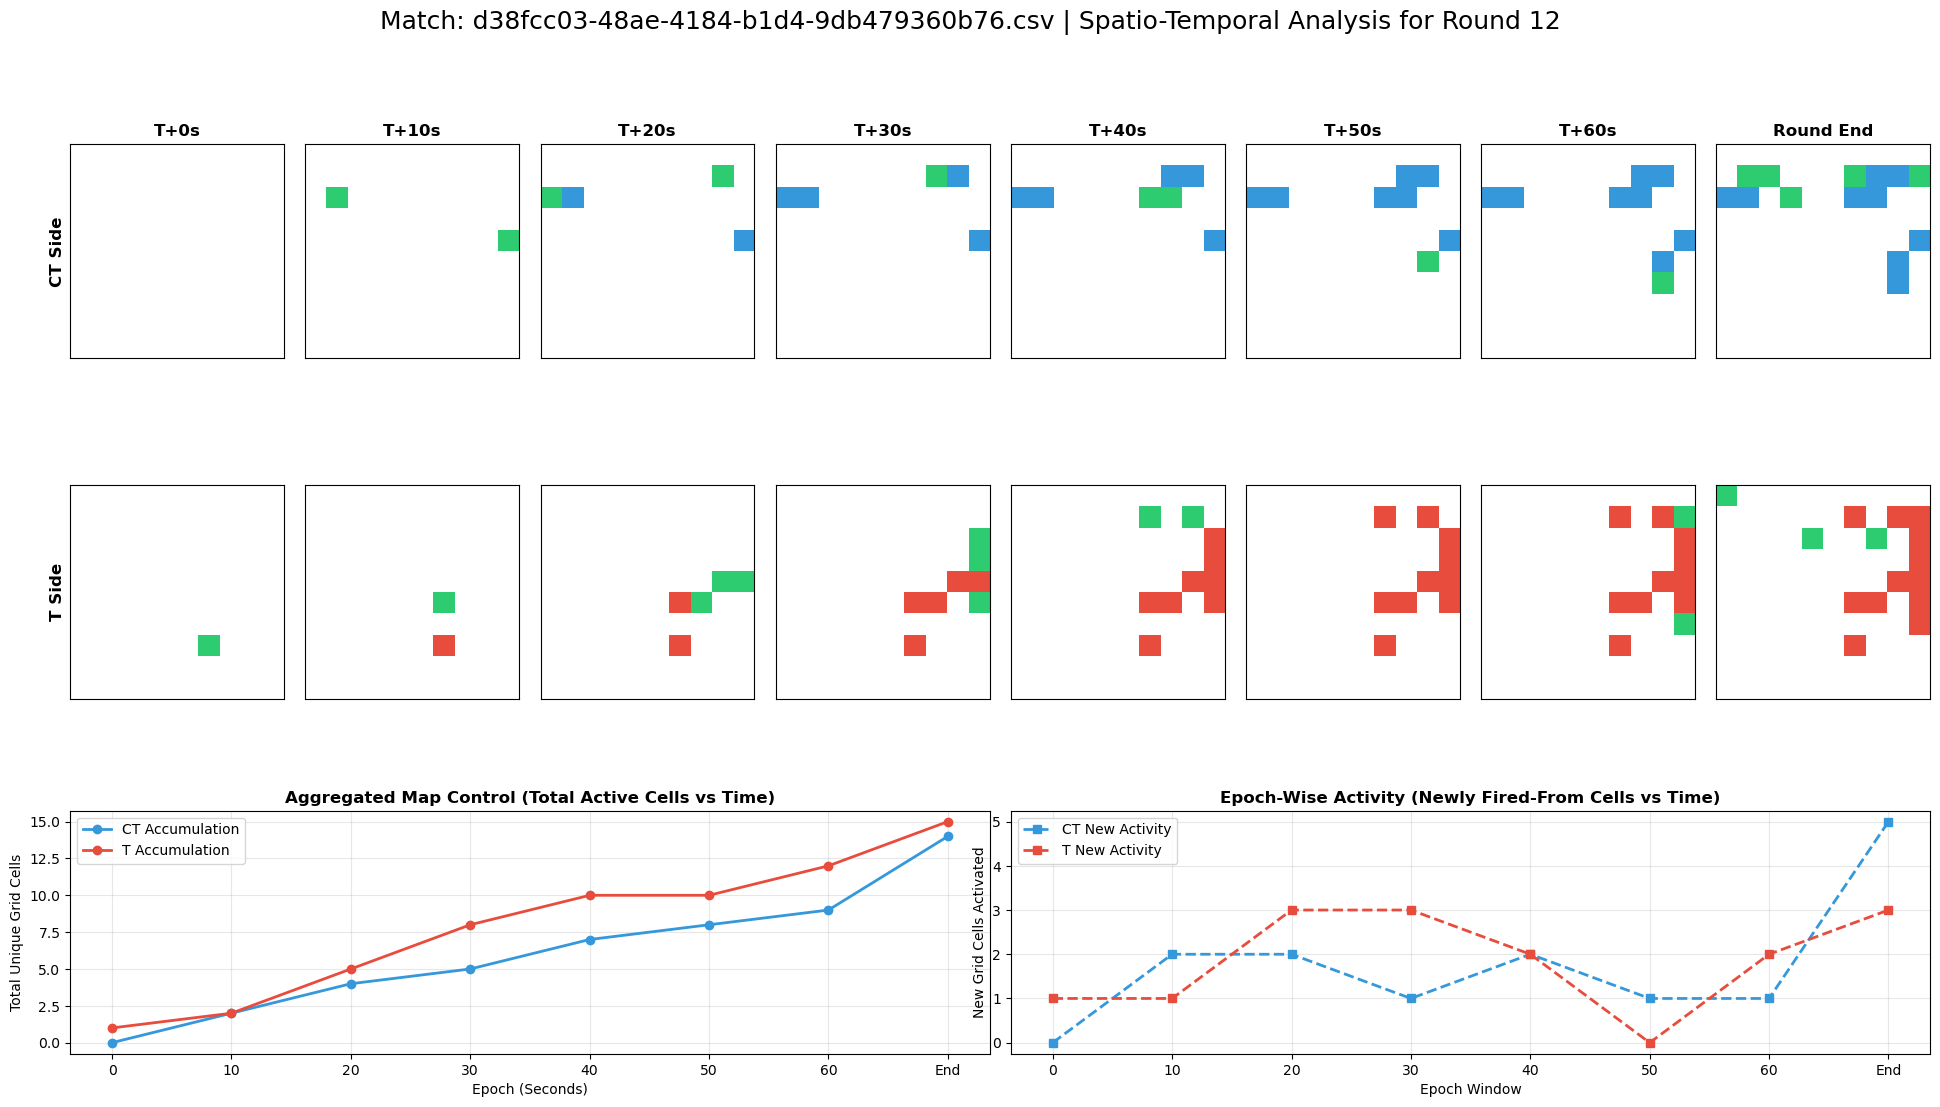

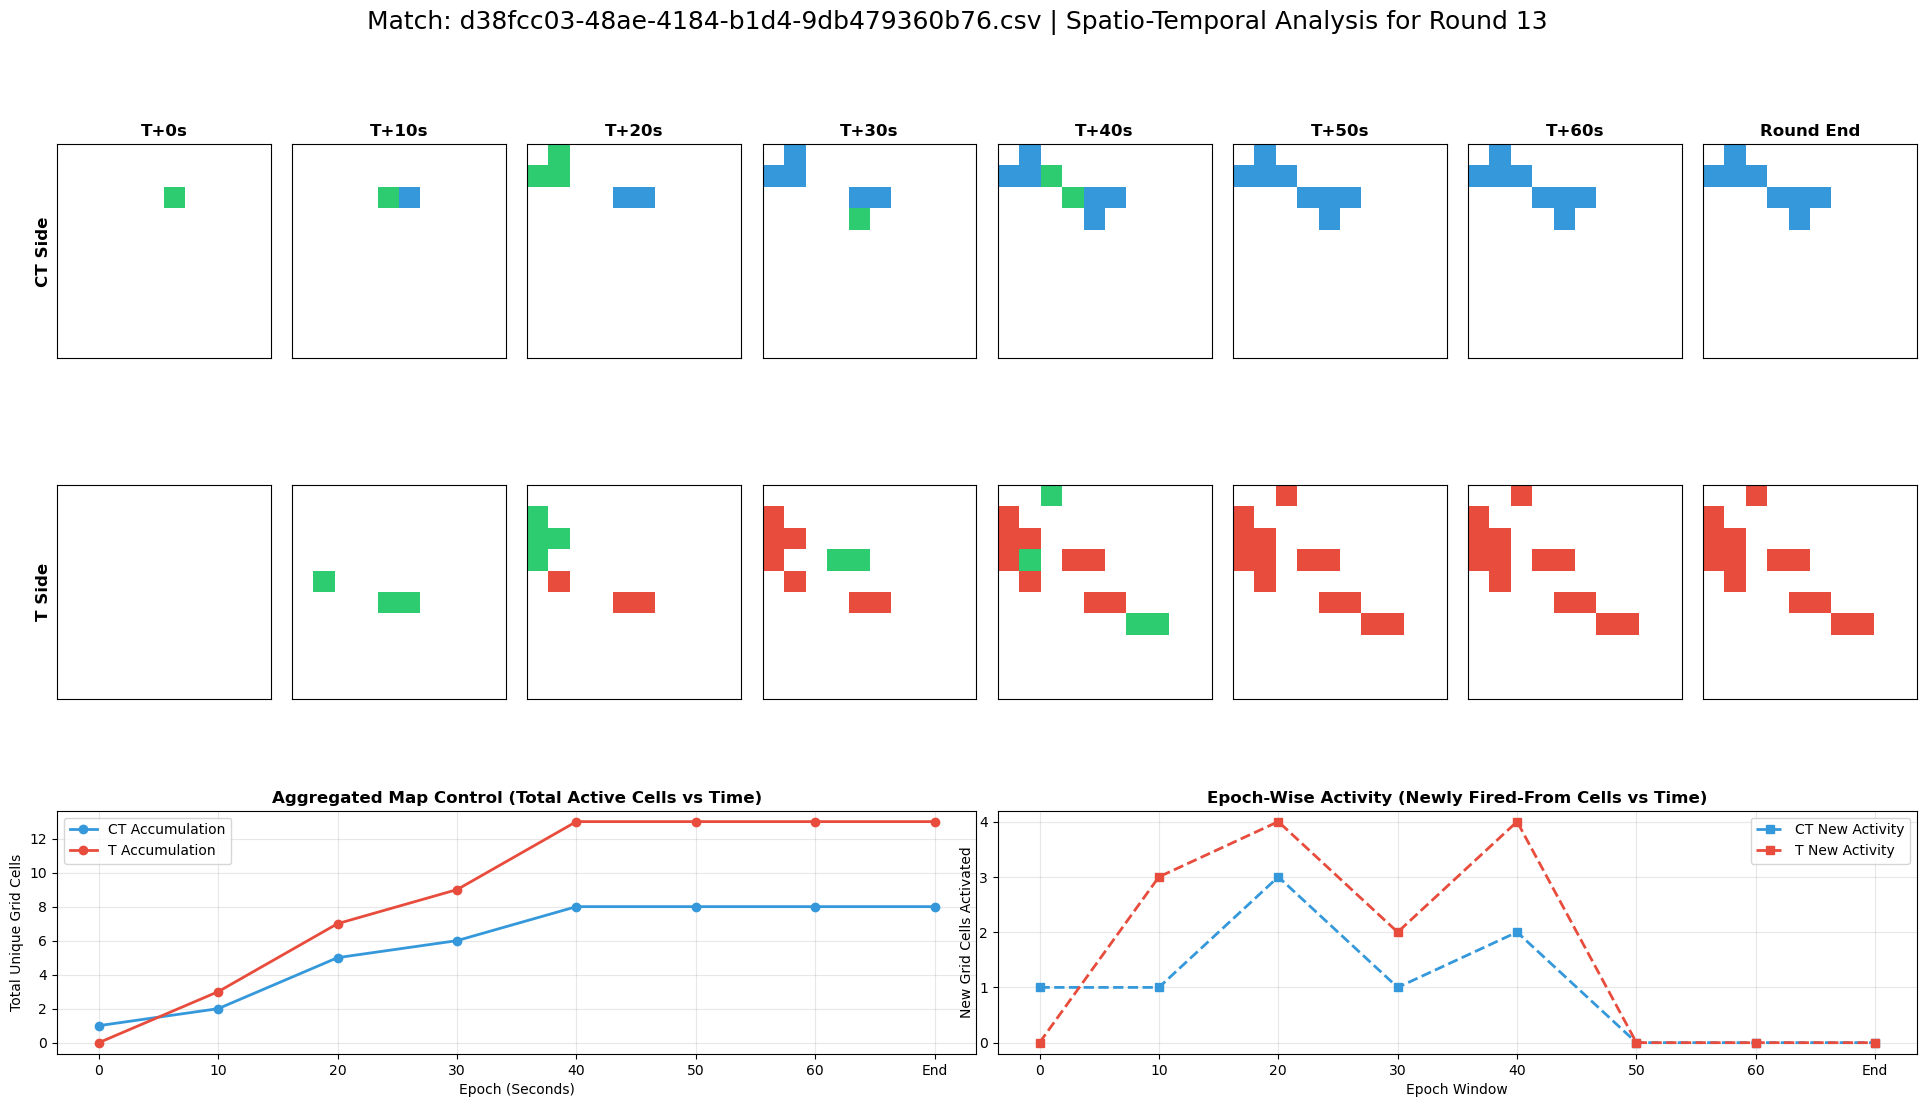

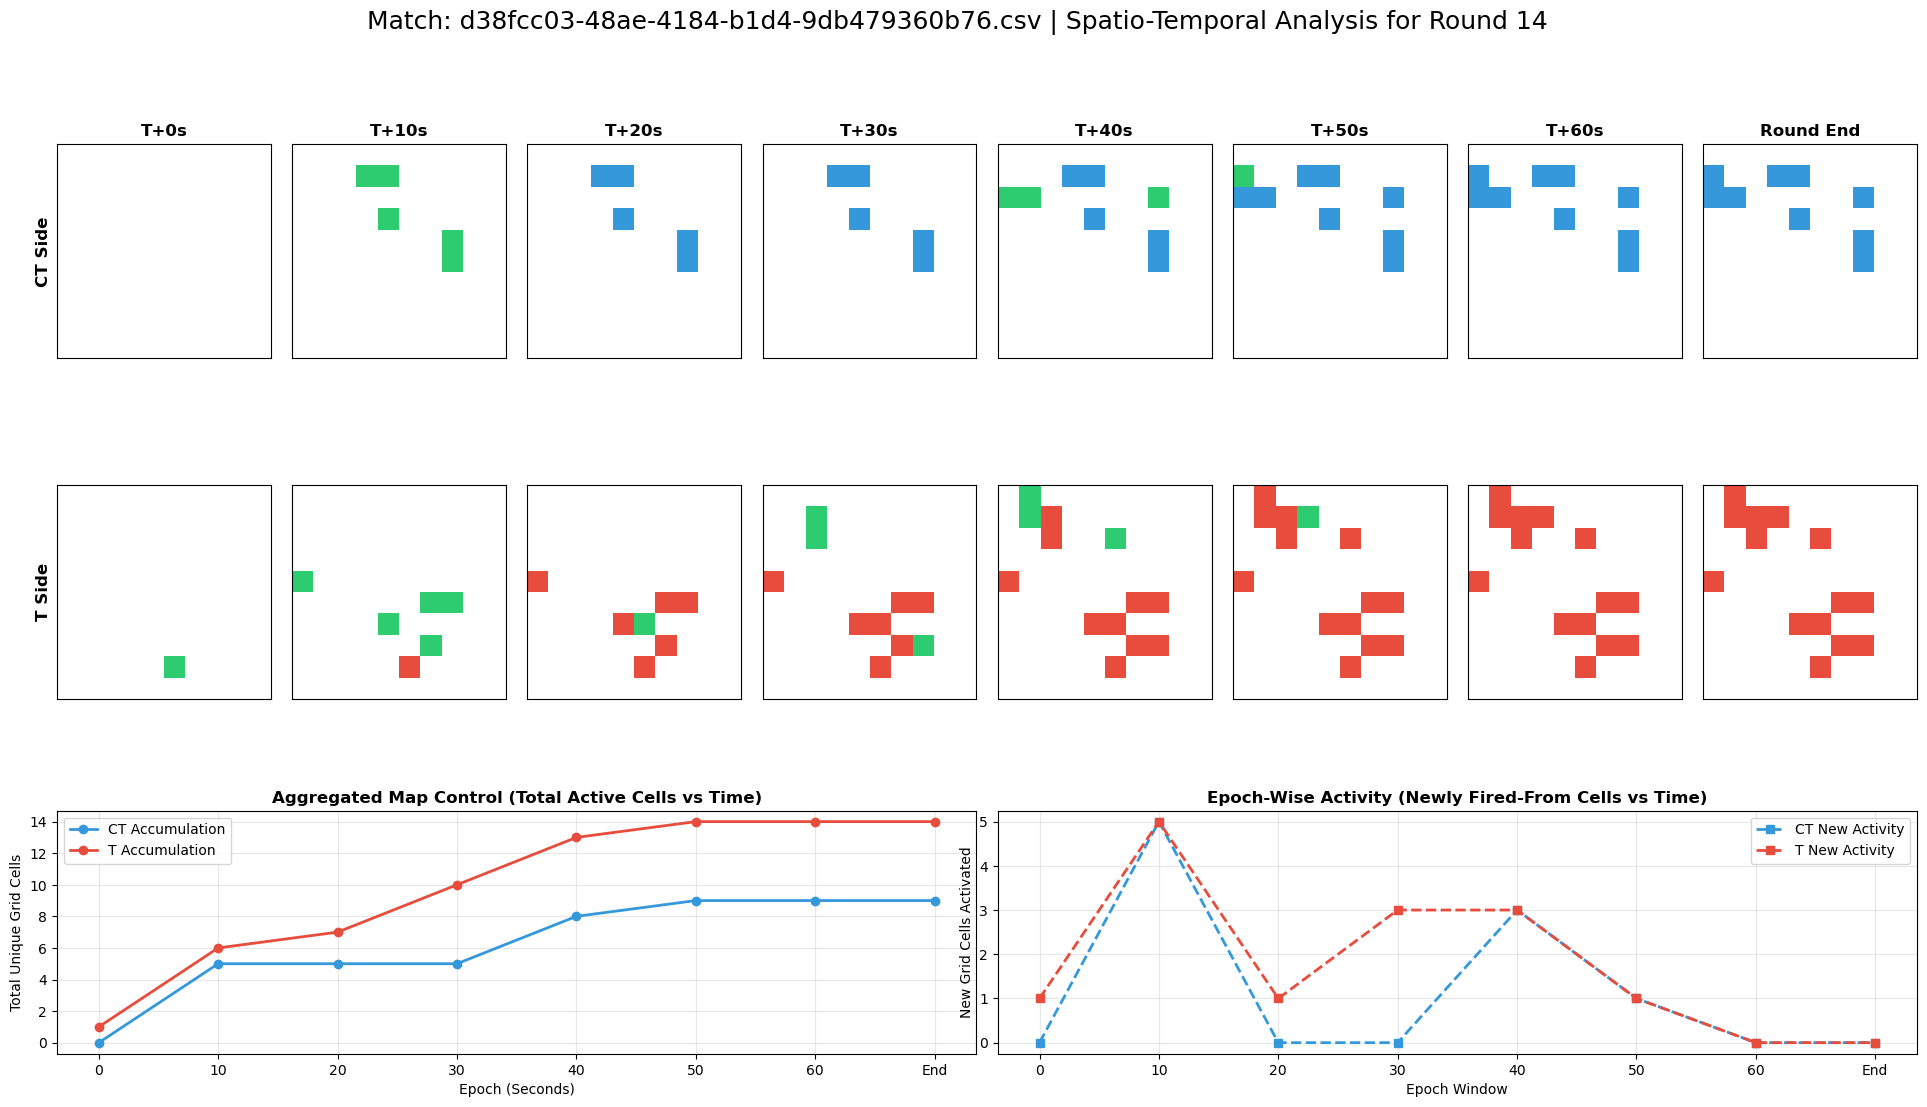

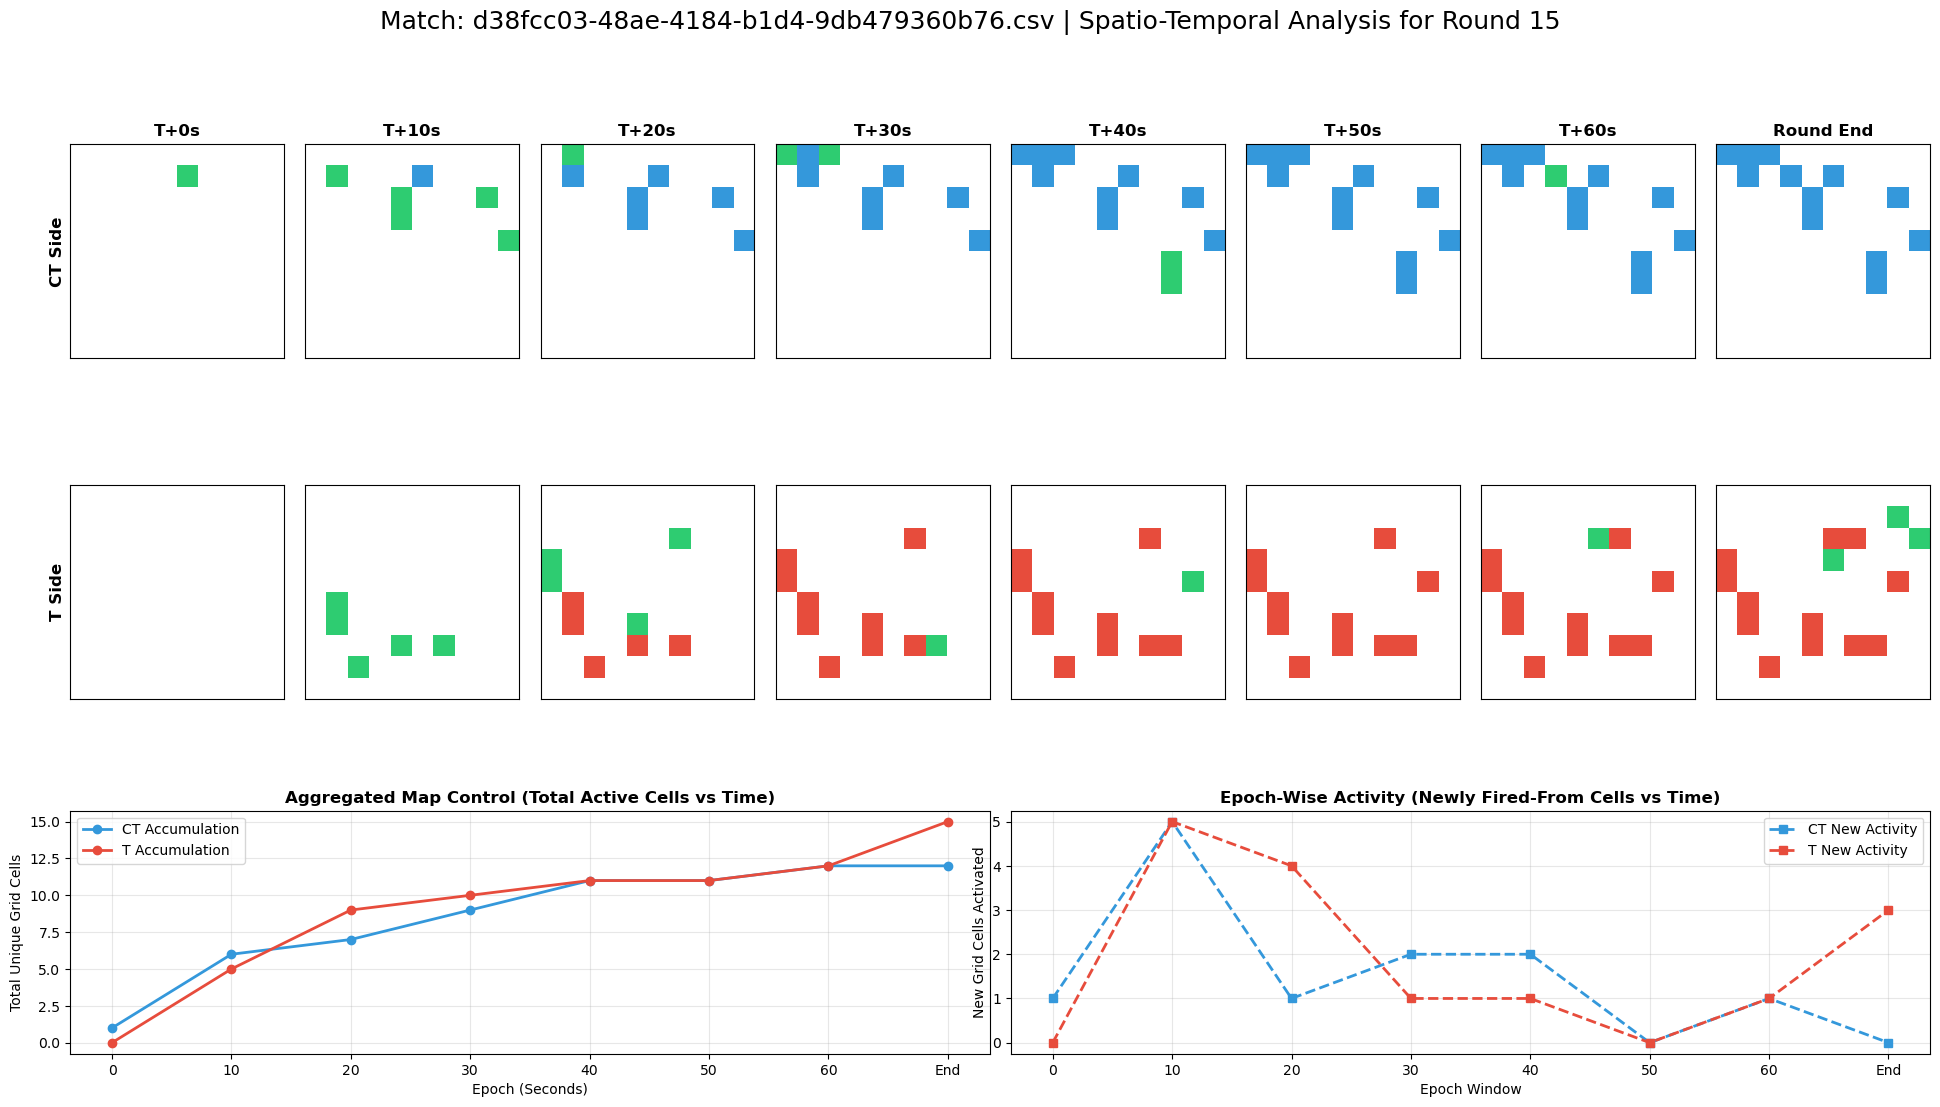

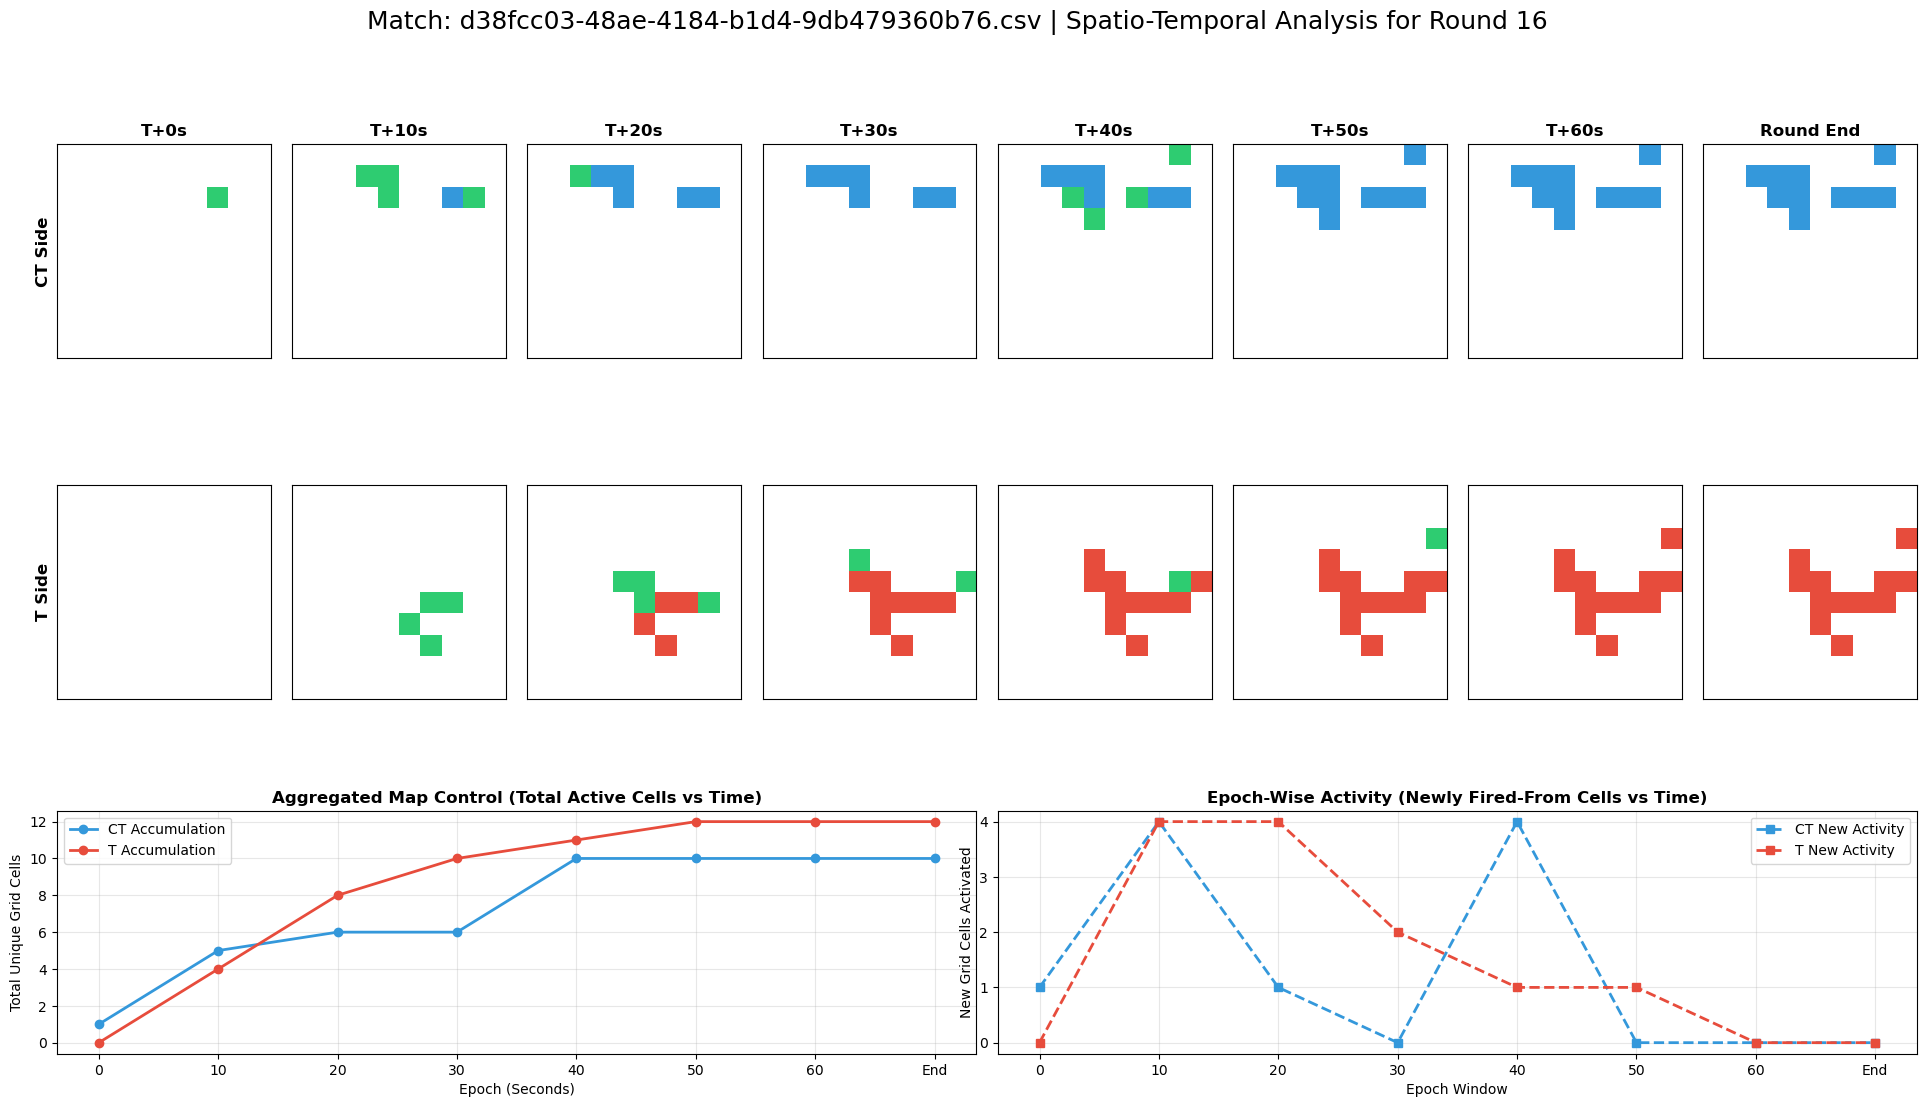

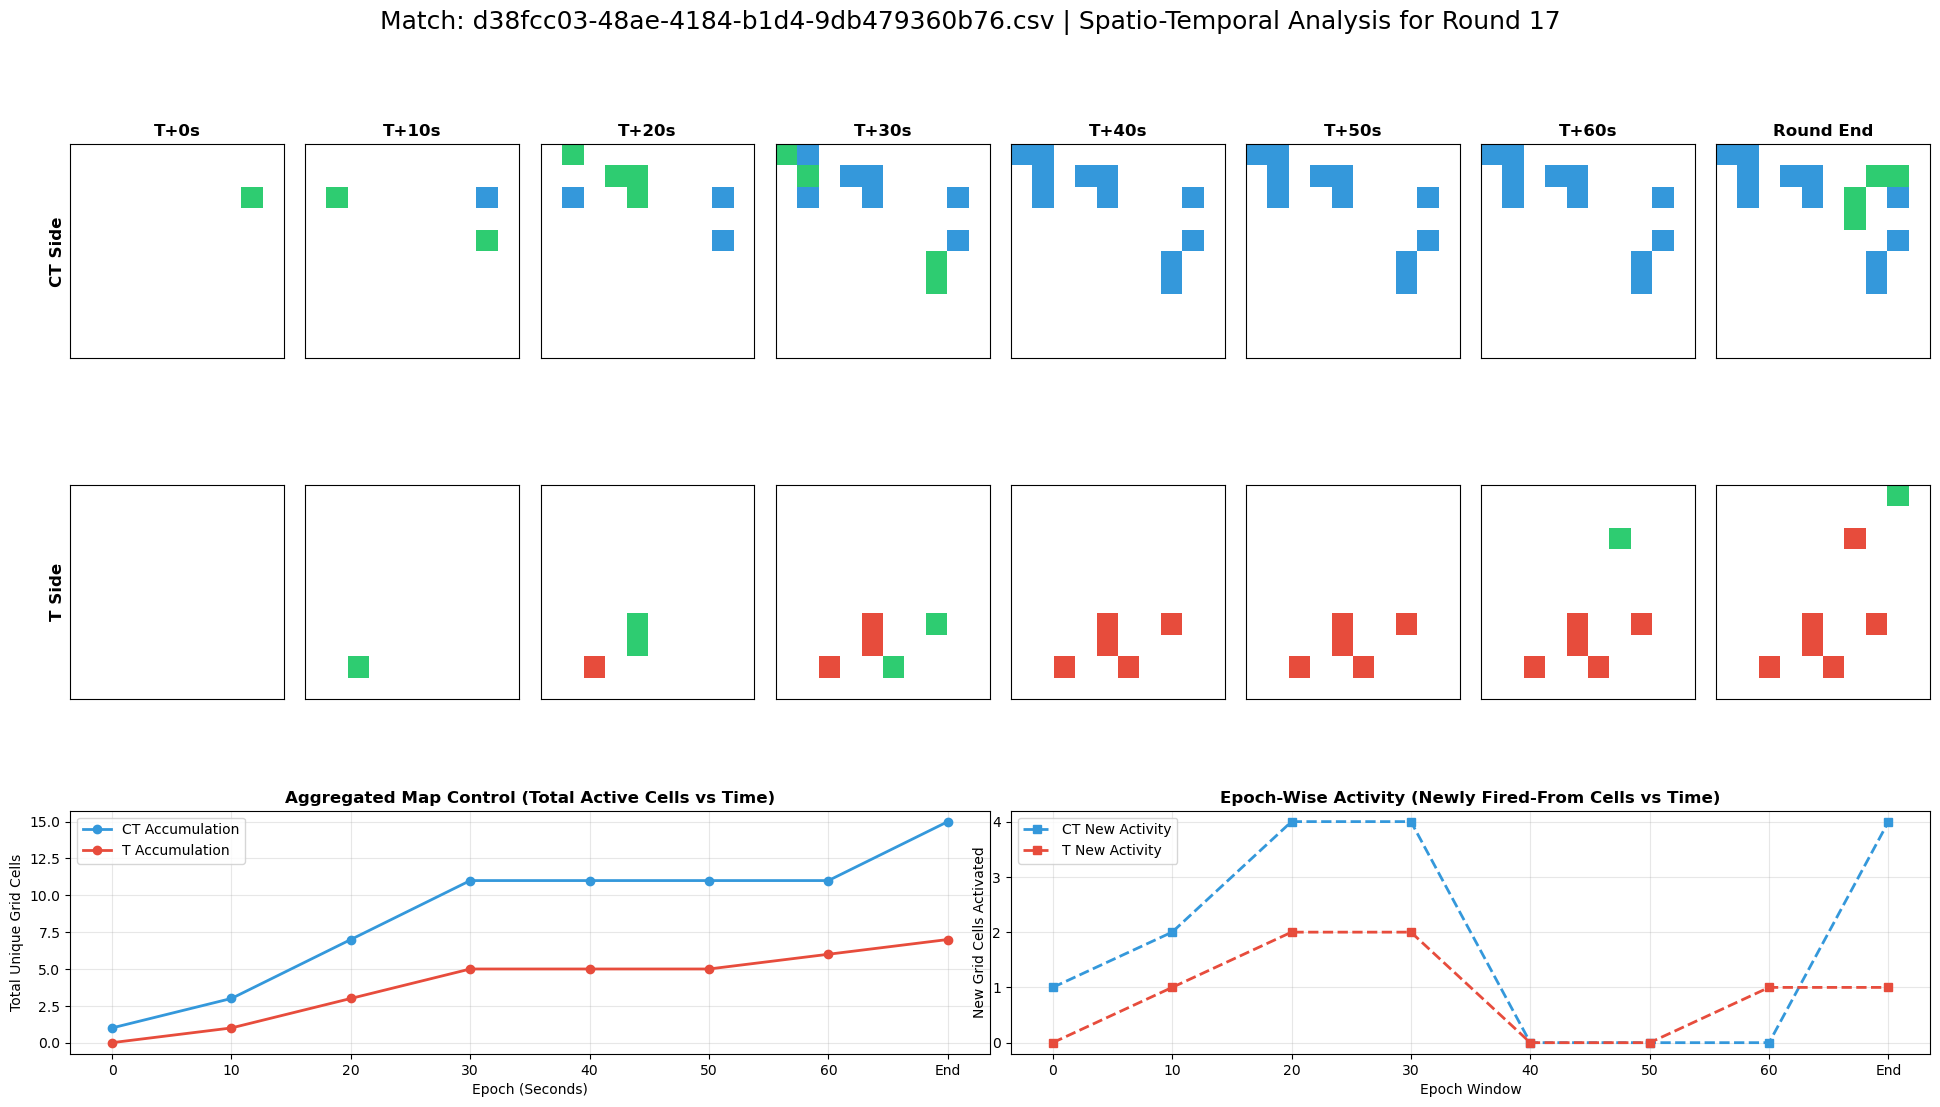

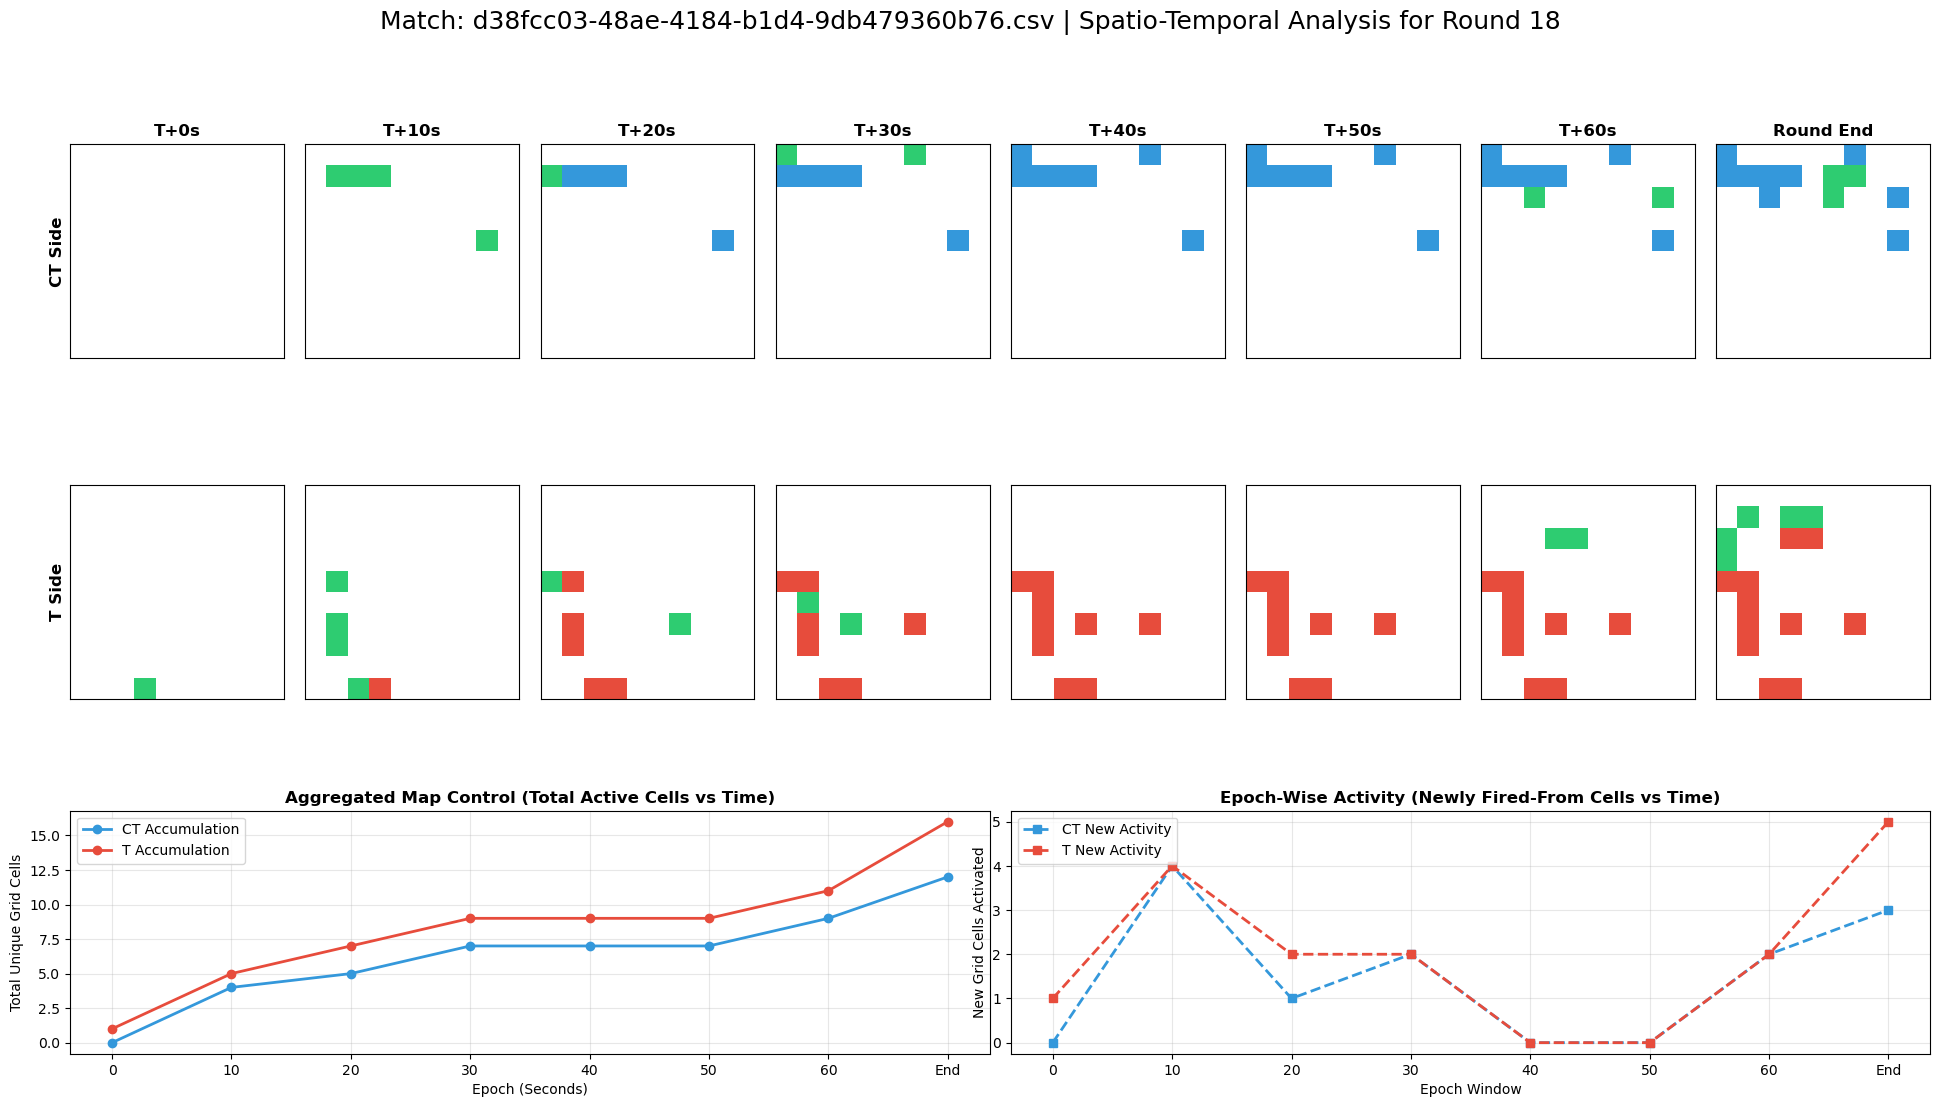

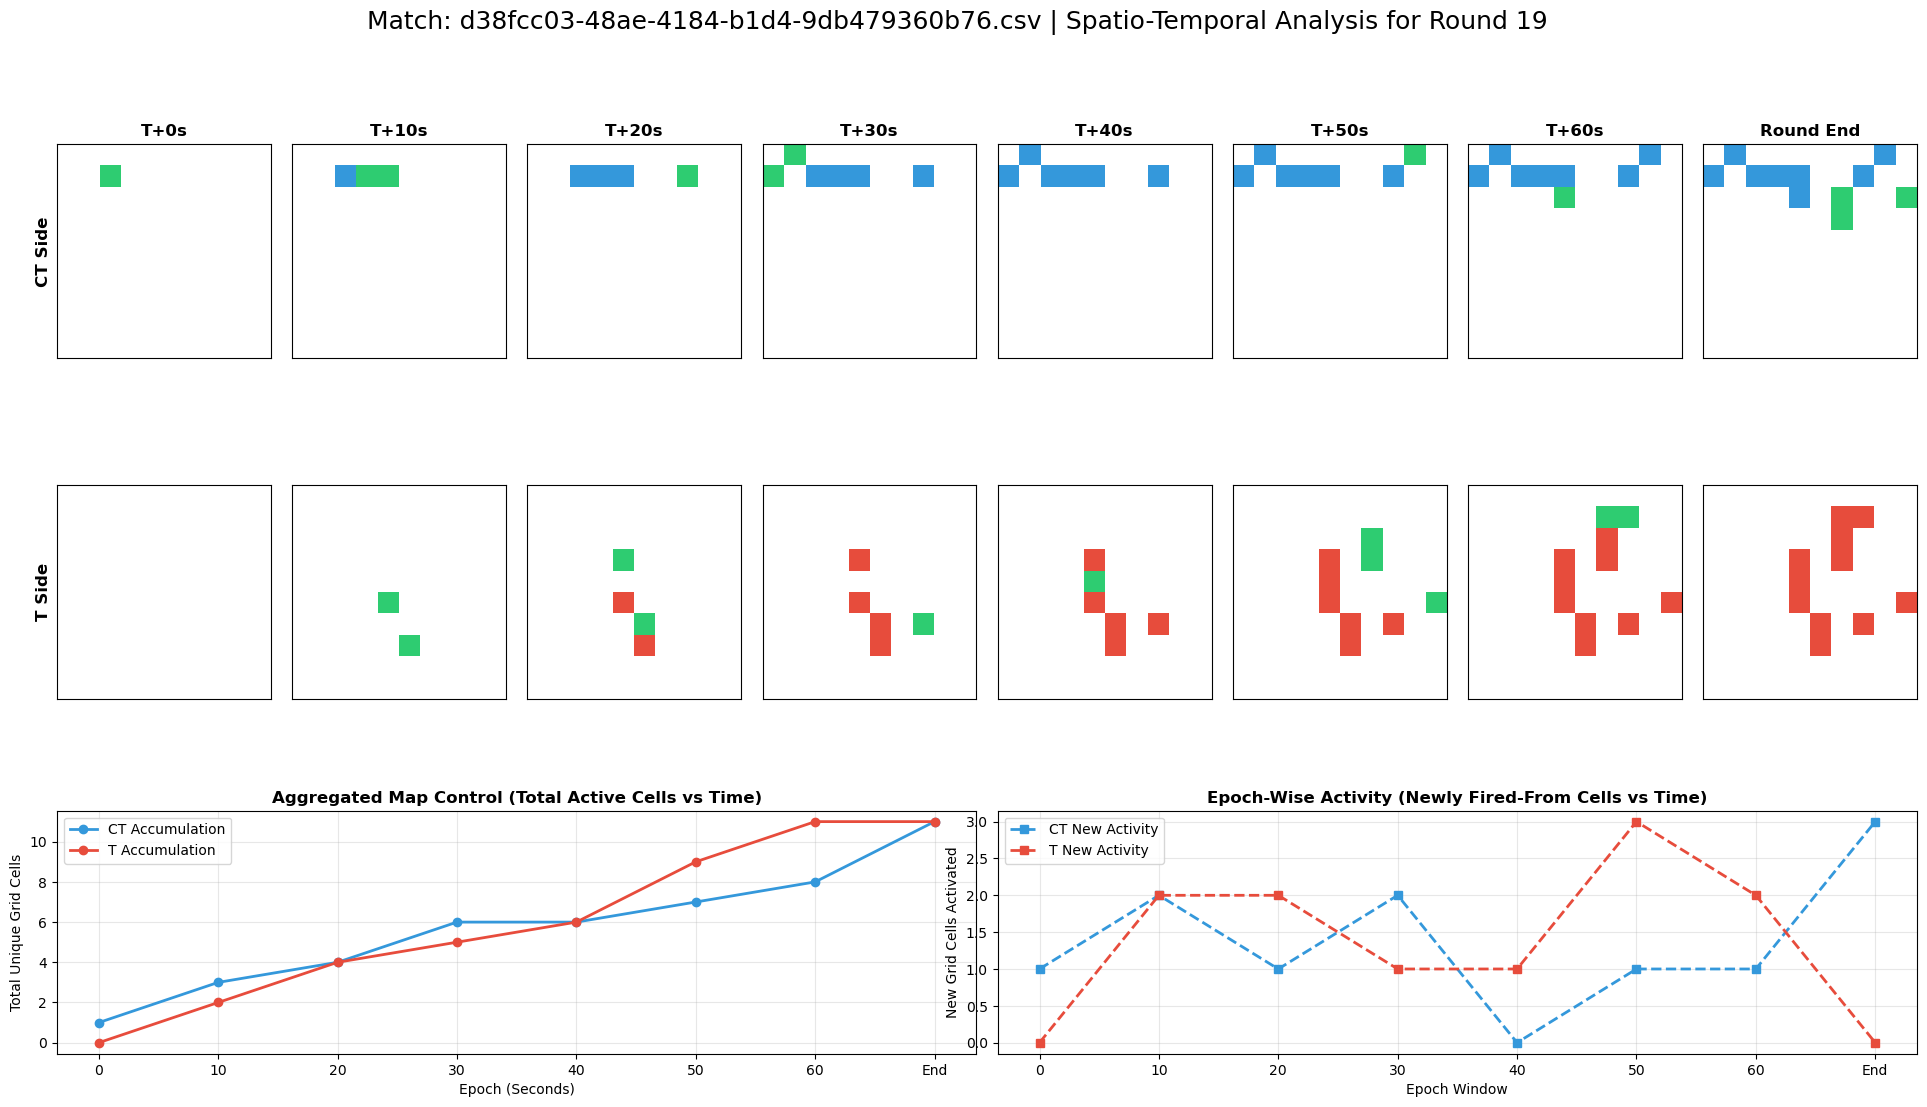

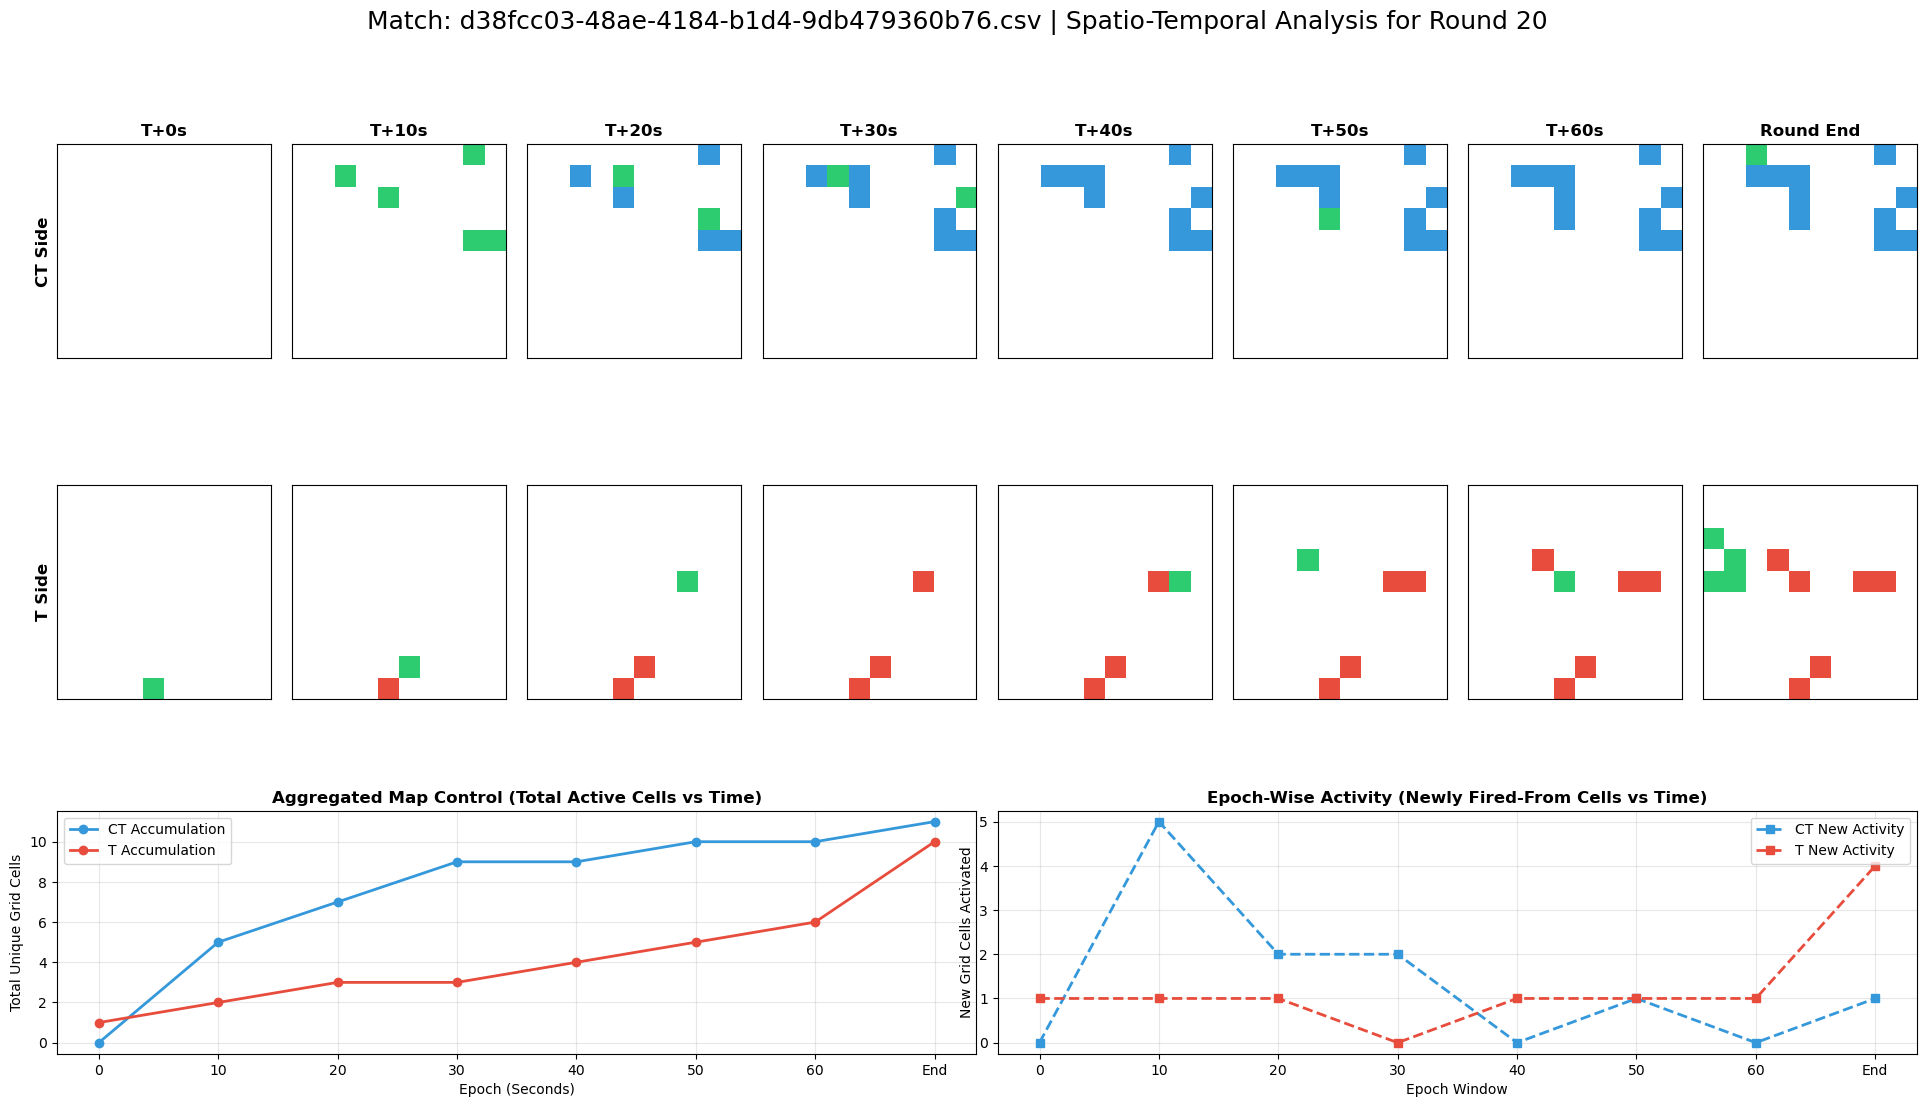

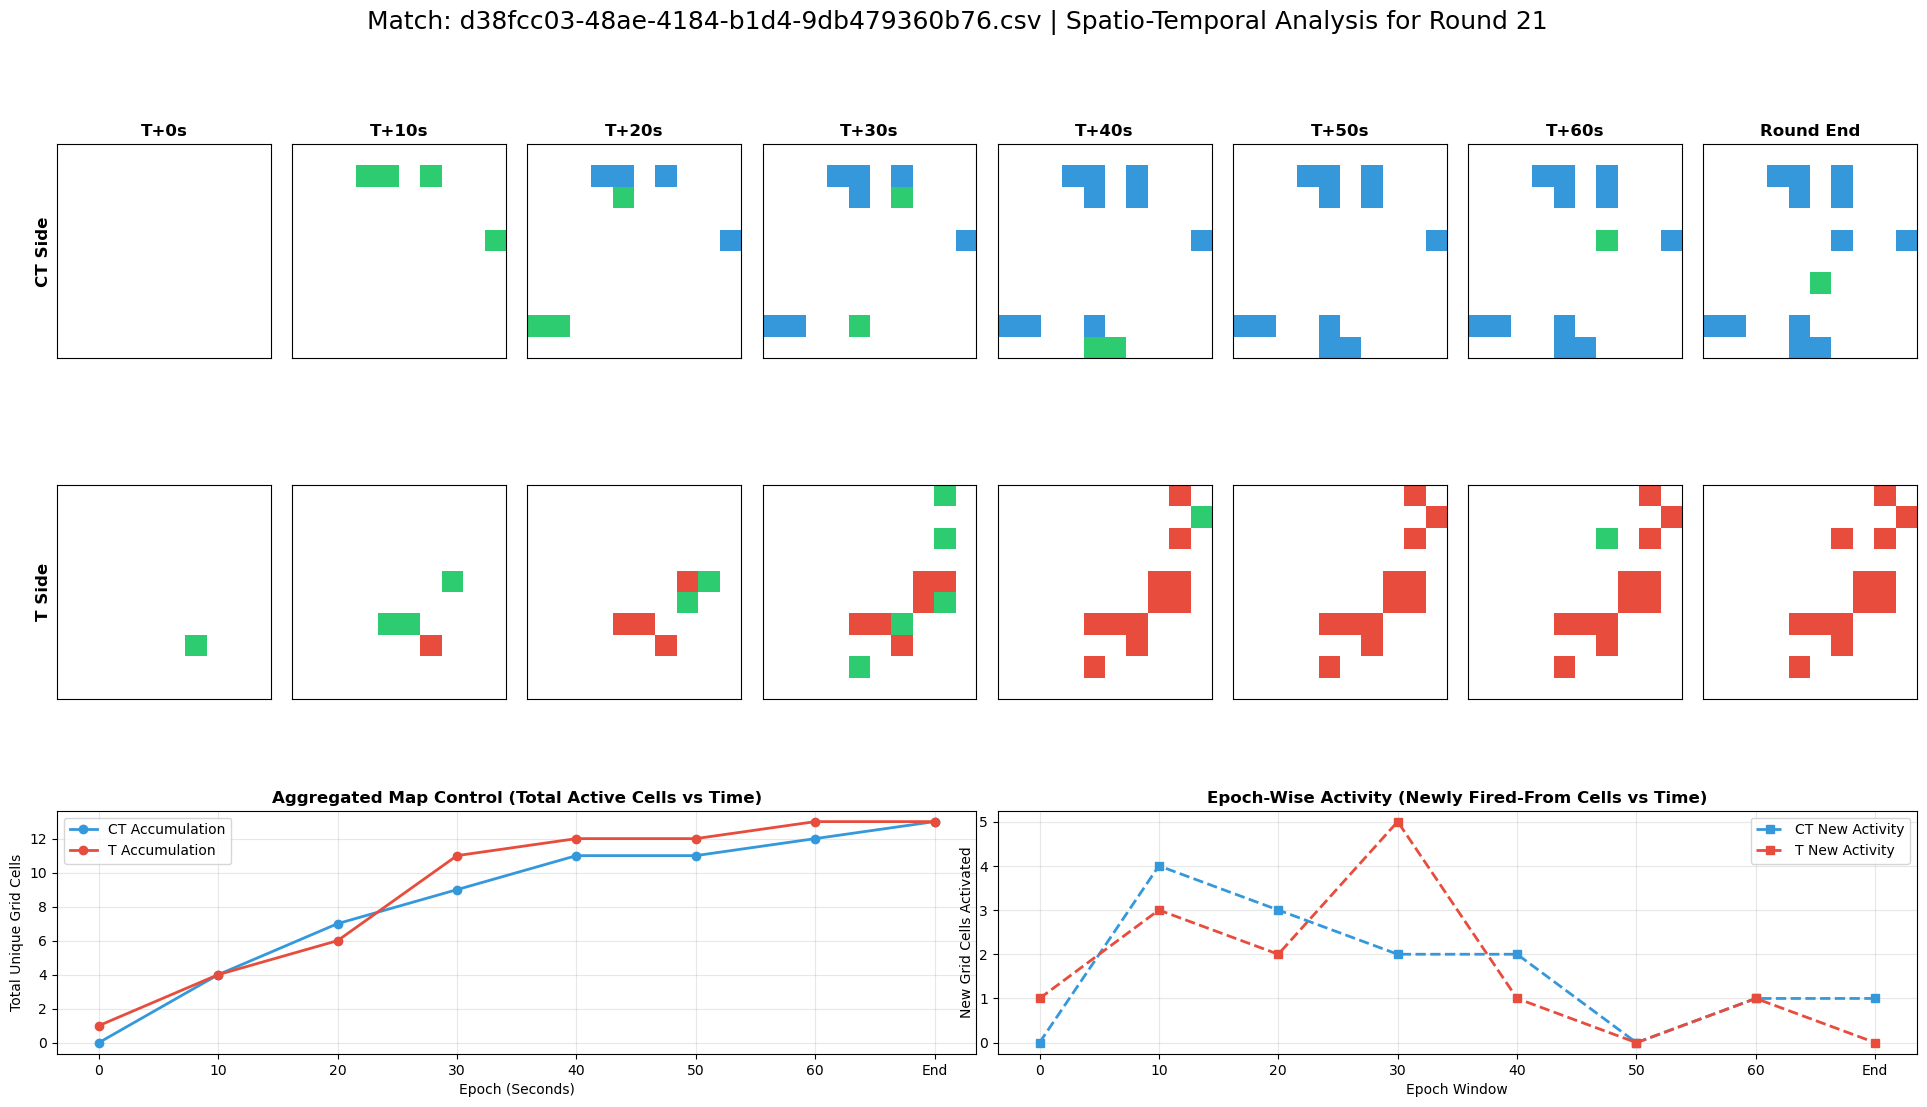

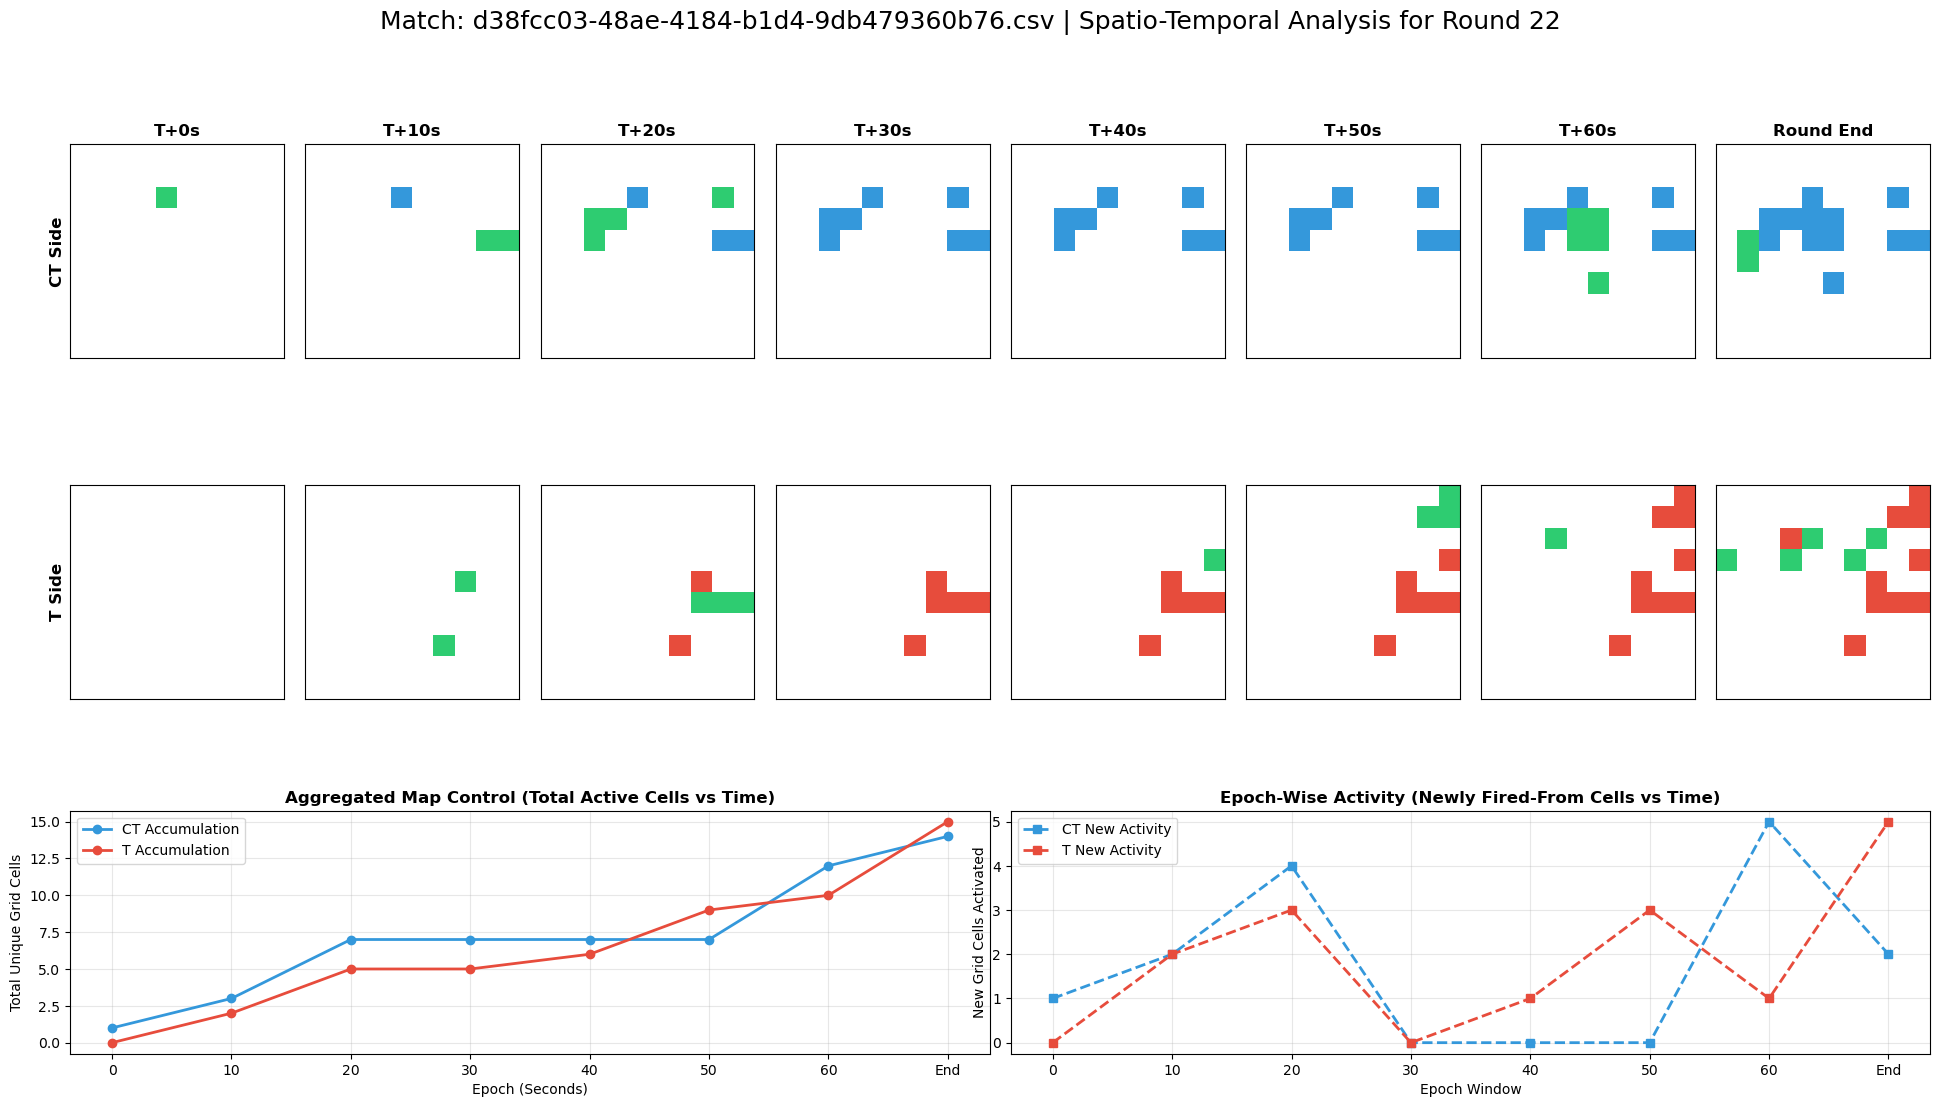

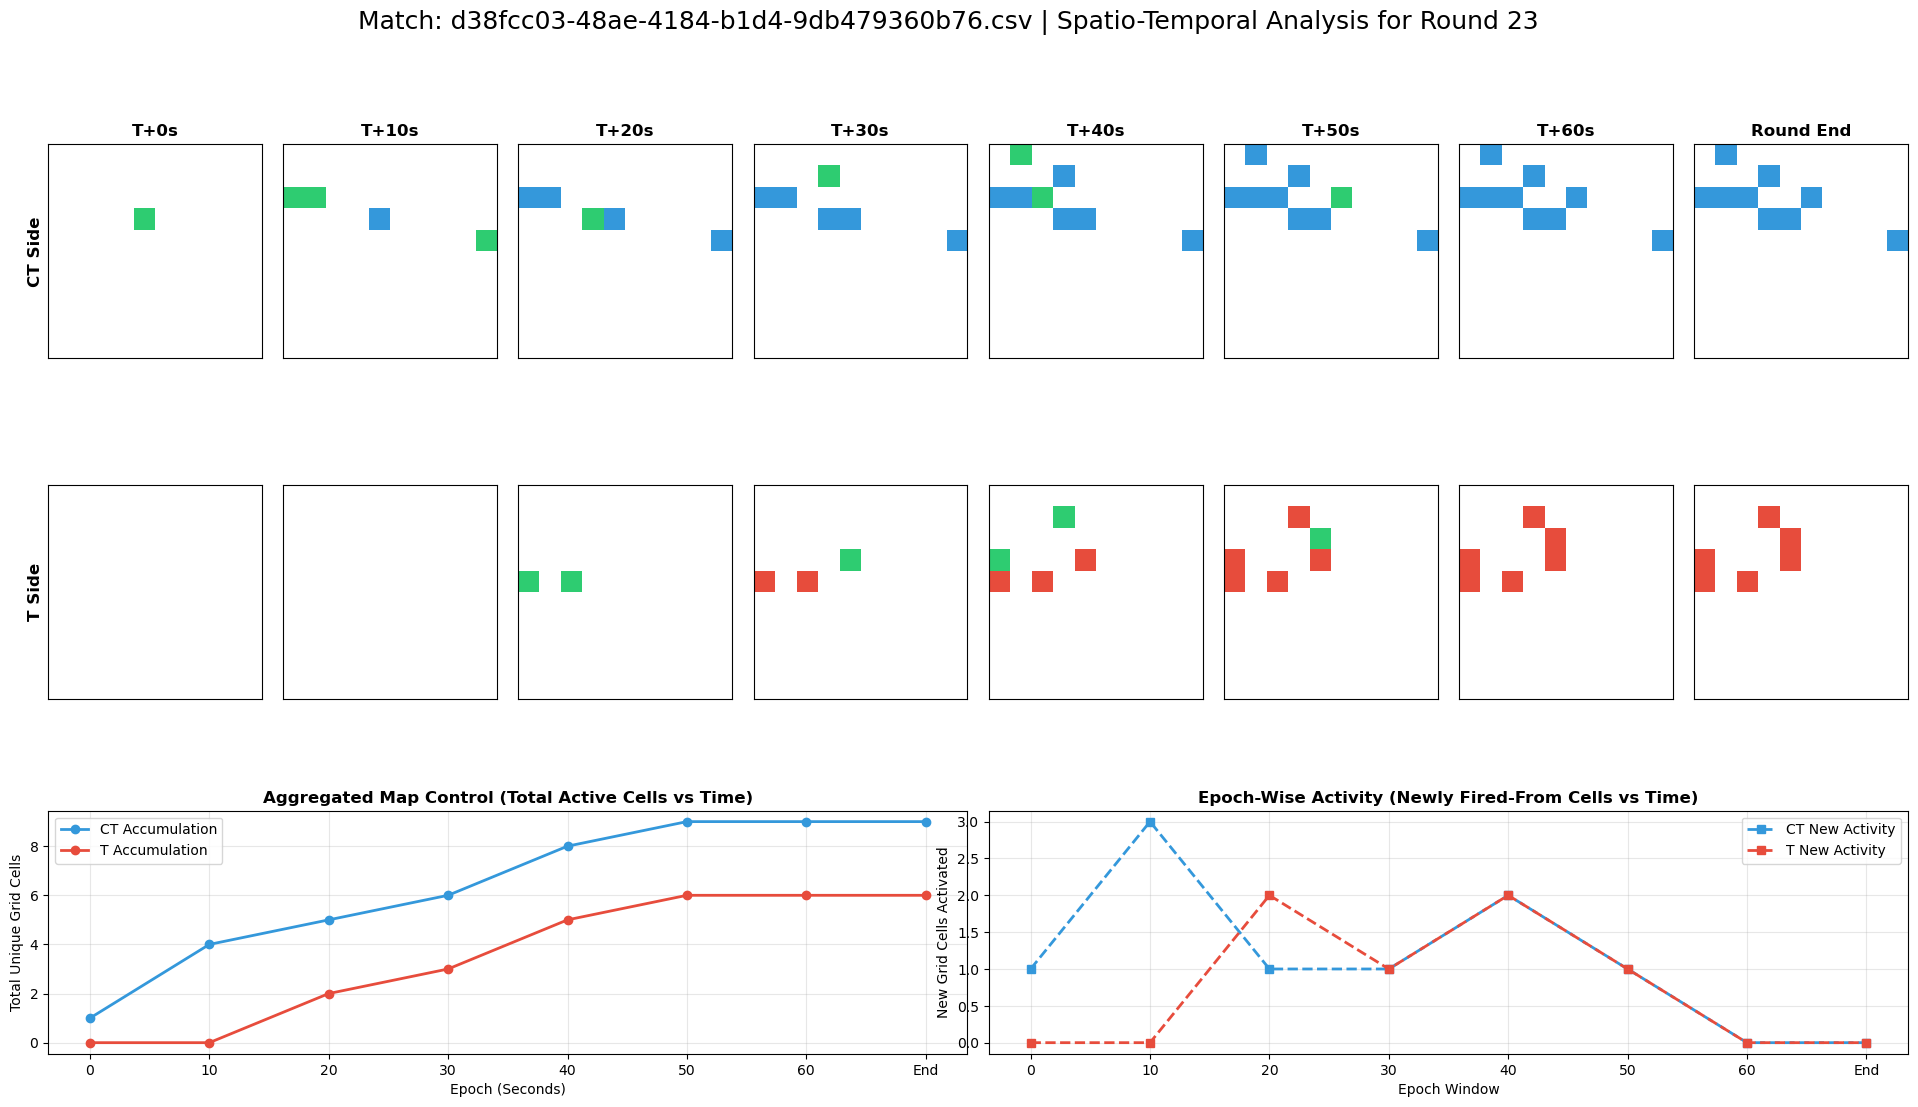

In [2]:
import os
import glob
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================
DATA_DIR = r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\FeatData\Wfire_STOMS_01\Training\Dust2"
EPOCHS = [0, 10, 20, 30, 40, 50, 60, "End"]
GRID_SIZE = 10

# ==========================================
# 2. FEATURE RETRIEVAL & USER SELECTION
# ==========================================
def select_match_file():
    """Lists available matches and prompts the user to select one by index."""
    if not os.path.exists(DATA_DIR):
        print(f"Error: Directory does not exist: {DATA_DIR}")
        return None

    # Find all CSV feature files in the directory
    files = glob.glob(os.path.join(DATA_DIR, "*.csv"))
    if not files:
        print("No CSV feature files found in the specified directory.")
        return None

    print("\n--- Available Matches ---")
    for idx, filepath in enumerate(files):
        print(f"[{idx}] {os.path.basename(filepath)}")

    # Handle user input
    while True:
        try:
            selection = int(input(f"\nEnter the index [0 to {len(files)-1}] of the match to visualize: "))
            if 0 <= selection < len(files):
                return files[selection]
            else:
                print("Invalid index. Please try again.")
        except ValueError:
            print("Please enter a valid number.")

# ==========================================
# 3. DATA PARSING & VISUALIZATION
# ==========================================
def visualize_match_stoms(filepath):
    """Loads the STOM features and visualizes the grids and collapsed metrics per round."""
    print(f"\nLoading data from: {os.path.basename(filepath)}")
    df = pl.read_csv(filepath)
    rounds = df["round"].to_list()

    for r_idx in range(len(rounds)):
        round_data = df.row(r_idx, named=True)
        r_id = round_data["round"]

        # Initialize data structures for collapsed metrics
        # aggregated = total map coverage | epoch_wise = newly fired cells in that window
        aggregated_counts = {"CT": [], "T": []}
        epoch_wise_counts = {"CT": [], "T": []}

        # Setup Figure using GridSpec (3 rows: CT maps, T maps, Line Plots)
        fig = plt.figure(figsize=(24, 12))
        gs = GridSpec(3, len(EPOCHS), figure=fig, hspace=0.4, wspace=0.1)

        # --------------------------------------------------
        # STOM Heatmaps (Rows 0 and 1)
        # --------------------------------------------------
        for side_idx, side in enumerate(["CT", "T"]):
            for epoch_idx, epoch in enumerate(EPOCHS):
                # Retrieve the 100 features for this specific Side and Epoch
                grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
                for i in range(GRID_SIZE * GRID_SIZE):
                    col_name = f"{side}_e{epoch}_cell_{i:02d}"
                    val = round_data.get(col_name, 0)
                    # Mapping flattened index back to 2D
                    r, c = divmod(i, GRID_SIZE)
                    grid[r, c] = val

                # Compute Collapsed Metrics (0=None, 1=History, 2=New Activity)
                total_cells_active = np.sum(grid > 0)
                new_cells_active = np.sum(grid == 2)
                
                aggregated_counts[side].append(total_cells_active)
                epoch_wise_counts[side].append(new_cells_active)

                # Plot Map
                ax = fig.add_subplot(gs[side_idx, epoch_idx])
                
                team_color = "#3498db" if side == "CT" else "#e74c3c"
                cmap = mcolors.ListedColormap(["#ffffff", team_color, "#2ecc71"]) # White, Team, Green
                
                ax.imshow(grid, cmap=cmap, origin='lower', vmin=0, vmax=2)
                ax.set_xticks([])
                ax.set_yticks([])
                
                if side_idx == 0:
                    ax.set_title(f"T+{epoch}s" if epoch != "End" else "Round End", fontweight='bold')
                if epoch_idx == 0:
                    ax.set_ylabel(f"{side} Side", fontweight='bold', fontsize=12)

        # --------------------------------------------------
        # Spatially Collapsed Maps - Aggregated (Row 2, Left)
        # --------------------------------------------------
        ax_agg = fig.add_subplot(gs[2, :len(EPOCHS)//2])
        x_labels = [str(e) for e in EPOCHS]
        
        ax_agg.plot(x_labels, aggregated_counts["CT"], marker='o', color="#3498db", label="CT Accumulation", linewidth=2)
        ax_agg.plot(x_labels, aggregated_counts["T"], marker='o', color="#e74c3c", label="T Accumulation", linewidth=2)
        ax_agg.set_title("Aggregated Map Control (Total Active Cells vs Time)", fontsize=12, fontweight='bold')
        ax_agg.set_xlabel("Epoch (Seconds)")
        ax_agg.set_ylabel("Total Unique Grid Cells")
        ax_agg.grid(True, alpha=0.3)
        ax_agg.legend()

        # --------------------------------------------------
        # Spatially Collapsed Maps - Epoch-wise (Row 2, Right)
        # --------------------------------------------------
        ax_epoch = fig.add_subplot(gs[2, len(EPOCHS)//2:])
        
        # Undo accumulation - plot only the new cells fired from in the current epoch window
        ax_epoch.plot(x_labels, epoch_wise_counts["CT"], marker='s', color="#3498db", linestyle="--", label="CT New Activity", linewidth=2)
        ax_epoch.plot(x_labels, epoch_wise_counts["T"], marker='s', color="#e74c3c", linestyle="--", label="T New Activity", linewidth=2)
        ax_epoch.set_title("Epoch-Wise Activity (Newly Fired-From Cells vs Time)", fontsize=12, fontweight='bold')
        ax_epoch.set_xlabel("Epoch Window")
        ax_epoch.set_ylabel("New Grid Cells Activated")
        ax_epoch.grid(True, alpha=0.3)
        ax_epoch.legend()

        # Render combined figure
        plt.suptitle(f"Match: {os.path.basename(filepath)} | Spatio-Temporal Analysis for Round {r_id}", fontsize=18, y=0.98)
        plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    selected_file = select_match_file()
    if selected_file:
        visualize_match_stoms(selected_file)